# Week 10 · Session 2 · Part A — Was it normal?
## Moving averages, decomposition, climatology and anomalies of NDVI in Saldaña

**Geoprocesamiento · Maestría en Geomática · Universidad Nacional de Colombia**

Today we ask two questions of a series that is already clean:

| Part | Question | Main ideas |
|---|---|---|
| **A (this notebook)** | **Was this period normal?** | moving averages, decomposition, climatology, anomalies |
| B | **Is something changing over the years?** | Mann–Kendall, Sen's slope, maps of trends |

### The one idea of the day
A satellite NDVI series is a **sum of parts that live at different time scales**:

$$ y(t) = \underbrace{S(t)}_{\text{seasonal cycle}} + \underbrace{I(\text{year})}_{\text{year-to-year}} + \underbrace{T(t)}_{\text{trend}} + \underbrace{\varepsilon(t)}_{\text{noise}} $$

The seasonal cycle $S$ is by far the largest part, and the least interesting for our questions. So every question starts by **removing parts, in order**:

| Step | Remove | What is left | Question it answers | Where |
|---|---|---|---|---|
| 1 | $S$ (subtract the typical year) | $I + T + \varepsilon$ = the **anomaly** | Was this period normal? | Part A |
| 2 | $\varepsilon$ (average each year) | $I + T$ | Is it changing? (the slope of a line) | Part B |
| 3 | $T$ (subtract the line) | $I$ | Which years were different? | Part B |

Before running each cell, ask yourself: **which part is this step removing, and which part is left?**

### The data
**MODIS** NDVI from its two satellites, **Terra** and **Aqua**: one 16-day composite each, shifted by 8 days, so together **one composite every 8 days, 46 per year**, at 250 m, for **2001–2015**. Our Sentinel-2 cube of Session 1 has only one year: with one year there is no "typical year" and no trend.

## 0 · Setup

**0.1 · The working folder.** Open Jupyter Lab from the course folder (Anaconda Prompt: `cd` to the folder, then `jupyter lab`). The folder must contain `src/ts_tools.py` and the `.h5` files. The cell checks it, and turns on *autoreload* so that changes to `ts_tools.py` are used without restarting.

In [161]:
# ---- Check the working folder (Jupyter Lab, Anaconda) ----
# Open Jupyter Lab FROM the course folder, the one that contains "src/ts_tools.py" and the .h5 files.
import os
print("Working folder:", os.getcwd())
print("Is the toolbox here?", os.path.exists("src/ts_tools.py"))

# If a library is missing, remove the "#" of ONE of these lines, run it once, then restart the kernel:
# %conda install -y -c conda-forge h5py scipy statsmodels folium pystac-client planetary-computer odc-stac
# %pip install h5py scipy statsmodels folium pystac-client planetary-computer odc-stac pymannkendall

# Autoreload: if you edit src/ts_tools.py, the notebook uses the new version without restarting the kernel.
%load_ext autoreload
%autoreload 2

Working folder: C:\Users\FCA-UN-2240386\OneDrive - Universidad Nacional de Colombia\1_Periodos_Asignaturas\Cursos_2026_2\Geoprocesamiento\notebooks_borrador\Anomalies
Is the toolbox here? True
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**0.2 · Libraries and toolbox.** The functions live in `src/ts_tools.py` (parts 5, 6 and 7 are new today). Use `help(tt.name)` whenever you are unsure what a function does.

In [162]:
import numpy as np                  # arrays and maths (means, medians, percentiles)
import pandas as pd                 # tables and dates
import matplotlib.pyplot as plt     # figures
import warnings
# With missing data numpy warns "mean of empty slice" when a whole group is NaN: expected, so we hide it
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})   # figure style for the whole notebook

from src import ts_tools as tt      # our toolbox: the file src/ts_tools.py, used with the short name "tt"
print("Toolbox loaded")

Toolbox loaded


**0.3 · Settings.** Everything we may want to change is written here, once.

🌎 **Your own study area.** This notebook is a template: to repeat it in your area, change `CENTRE_LAT`, `CENTRE_LON` (the centre, in degrees), `HALF` (half the width of the window, in degrees: 0.09 ≈ 10 km), `CRS` if your area is in another UTM zone (`EPSG:326xx` north of the equator, `EPSG:327xx` south), and the name of `MODIS_FILE`, so that the file of Saldaña is not overwritten. Then run everything again: the first time, the cube is downloaded and saved.

The window (about 20 × 20 km) is larger than in Session 1: with 250 m pixels a small window would have very few pixels, and this one includes irrigated rice, riparian forest and the sand bars of the river.

In [163]:
# The area: centre of the Saldaña irrigation district and half the width of the window (degrees)
CENTRE_LAT, CENTRE_LON, HALF = 3.915, -74.985, 0.09     # 0.09 degrees ≈ 10 km, so the window is ≈ 20 x 20 km
# BBOX = [west, south, east, north] in degrees: the rectangle that is downloaded
BBOX = [CENTRE_LON - HALF, CENTRE_LAT - HALF, CENTRE_LON + HALF, CENTRE_LAT + HALF]

PERIOD = "2001-01-01/2015-12-31"          # 15 complete years
P = 46                                    # composites per year (Terra + Aqua, every 8 days)
REF_YEARS = (2001, 2015)                  # the reference period of the climatology: always declare it
CRS = "EPSG:32618"                        # UTM zone 18 N (Saldaña); change it for another zone
MODIS_FILE = "saldana_modis_ndvi_2001_2015_terra_aqua.h5"

# ENSO episodes, APPROXIMATE (check them against NOAA's tables). Used only to shade figures.
ENSO = [("El Niño", "2002-06", "2003-02"), ("La Niña", "2007-08", "2008-05"),
        ("El Niño", "2009-07", "2010-04"), ("La Niña", "2010-07", "2011-04"),
        ("La Niña", "2011-08", "2012-03"), ("El Niño", "2015-03", "2015-12")]

**0.4 · The MODIS cube.** As in Session 1, the cube is **built once and saved with its decisions**. If the file is in your folder (your lecturer may share it), the function only reads it. If not, it downloads MOD13Q1 (Terra) and MYD13Q1 (Aqua) from Planetary Computer, keeps the pixels with *pixel reliability* 0 (good) or 1 (marginal), converts to NDVI (× 0.0001) and saves the file. ⏳ The first time takes several minutes.

The time axis is **regular**: a composite without data is a layer of NaN, not a missing date (for example, all Aqua composites before July 2002).

In [164]:
# Read the file if it exists; if not, download from Planetary Computer, save it, and then read it
cube = tt.get_modis_file(MODIS_FILE, BBOX, PERIOD, crs=CRS, title="MODIS Terra + Aqua NDVI, 2001-2015")

# "cube" is a dictionary: each key is one piece of the file
ndvi = cube["ndvi"]                       # the NDVI values: a 3-D array (time, rows, columns); NaN = no reliable value
dates = pd.DatetimeIndex(cube["time"])    # the date of each layer (one every 8 days)
print("Shape (time, rows, columns):", ndvi.shape)
print("First and last date:", dates[0].date(), "->", dates[-1].date())
print("Layers per year:", len(dates) // 15)   # should be 46: 23 from Terra + 23 from Aqua

Shape (time, rows, columns): (690, 80, 81)
First and last date: 2001-01-01 -> 2015-12-27
Layers per year: 46


In [165]:
# The decisions stored in the file (its "attributes"): where the data come from, which pixels were kept, etc.
for key, value in cube["attrs"].items():
    print(f"{key:15s}: {value}")          # {key:15s} writes the name in a column 15 characters wide

bbox_wgs84     : [-75.075, 3.825, -74.895, 4.005]
created        : 2026-11-16 17:28
crs            : EPSG:32618
mask_rule      : pixel_reliability in (0, 1) kept; 2 (snow) and 3 (cloudy) -> NaN
period         : 2001-01-01/2015-12-31
resolution_m   : 250.0
scale_rule     : NDVI = DN x 0.0001; DN = -3000 -> NaN
source         : MOD13Q1 (Terra) + MYD13Q1 (Aqua) v061, Microsoft Planetary Computer
time_axis      : regular axis; a missing composite is a layer of NaN
title          : MODIS Terra + Aqua NDVI, Saldaña, 2001-2015


**0.5 · A first look.**

- **Left: where is the vegetation?** The median NDVI of each pixel over the 15 years (2001–2015). High values (green) are dense vegetation, such as the riparian forest along the river. Low values are bare soil, sand bars, water or built-up areas. The median gives one "typical" value per pixel; one cloudy or extreme date does not change it.
- **Right: how much evidence do we have each year?** The share of the window with a usable value.
  - A pixel counts as usable only if MODIS rated it **reliable**, that is, *pixel reliability* 0 (good) or 1 (marginal).
  - Pixels with clouds (3), snow (2) or no data (−1) were set to NaN when the cube was built, so they do not count.
  - A bar of 0.8 means that, on average, 80 % of the window had a value in that year's composites.

> ⚠️ **2001 and 2002 are lower for another reason.** Aqua started in July 2002, so in 2001 and the first half of 2002 half of the 8-day layers are empty. The drop in those years is a gap in the data, not a cloudier year.

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words.
> 1. Find the river and the rice fields in the left map. Which has the higher median NDVI, and why?
> 2. Leaving out 2001 and 2002, which year has the least evidence? Is it a La Niña year (wetter, cloudier)?
> 3. Why does it matter for an anomaly how much evidence there is that year?

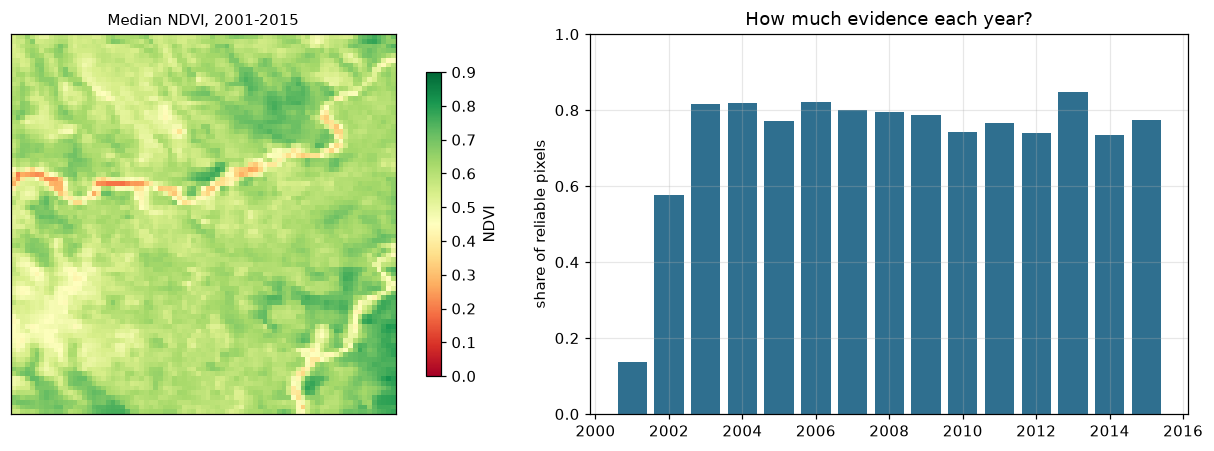

In [166]:
# axis=0 is time: the median over all the layers leaves ONE value per pixel (a map)
median_map = np.nanmedian(ndvi, axis=0)

# A pixel has a value (not NaN) only if MODIS rated it reliable: pixel reliability 0 (good) or 1 (marginal).
# Clouds (3), snow (2) and no data (-1) were set to NaN when the cube was built.
# np.isfinite is True where there is a value; its mean over rows and columns (axis=(1, 2))
# is the share of the window with usable data, ONE value per layer.
share_valid = np.isfinite(ndvi).mean(axis=(1, 2))
# group the layers by year and average: one share per year
share_by_year = pd.Series(share_valid, index=dates).groupby(dates.year).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))         # a figure with two panels side by side
im = tt.show_map(axes[0], median_map, "Median NDVI, 2001-2015")
plt.colorbar(im, ax=axes[0], shrink=0.8, label="NDVI")
axes[1].bar(share_by_year.index, share_by_year.values, color="#2F6F8F")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("share of pixels with usable data\n(reliability 0 or 1)")
# 2001 and early 2002: Aqua had not started yet, so half of the 8-day layers are empty
axes[1].set_title("How much evidence each year?\n(2001-2002 lower: Aqua starts in July 2002)")
plt.tight_layout(); plt.show()

**0.6 · Are Terra and Aqua comparable?** Joining two satellites doubles the data only if they measure the same thing. Terra passes in the morning and Aqua in the afternoon. We compare each Aqua composite with the Terra composite of 8 days before (window mean). The points should fall close to the 1:1 line.

Number of pairs: 309
Median difference Aqua - Terra: -0.006 NDVI


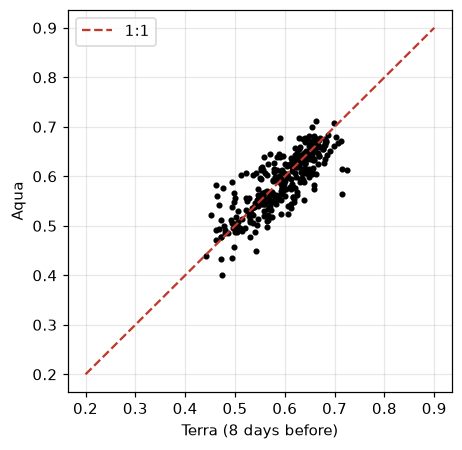

In [167]:
# The provenance table says which satellite made each layer ("terra" or "aqua")
platform = cube["provenance"]["platform"].values
# One row per Aqua layer: the window-mean NDVI of Aqua and of the Terra layer of 8 days before
pairs = tt.compare_terra_aqua(ndvi, dates, platform)
difference = pairs["aqua"] - pairs["terra_8_days_before"]
print("Number of pairs:", len(pairs))
print(f"Median difference Aqua - Terra: {difference.median():+.3f} NDVI")   # close to 0 = they agree

plt.figure(figsize=(4.5, 4.5))
plt.plot(pairs["terra_8_days_before"], pairs["aqua"], ".", color="k")      # one point per pair
plt.plot([0.2, 0.9], [0.2, 0.9], "--", color="#C0392B", label="1:1")       # where Aqua = Terra
plt.xlabel("Terra (8 days before)"); plt.ylabel("Aqua"); plt.legend(); plt.show()

Part of the difference is real change in 8 days, so it is never exactly zero. What matters is that it is **small**: if Aqua were systematically higher, a change in the proportion of Terra and Aqua values could create a false trend.

# Part A · Was it normal?

### A1 · Choose three pixels, one per land cover
We will follow three pixels through the whole notebook, one for each kind of vegetation in the window:

| Class | What to look for on the image | Expected NDVI through the year |
|---|---|---|
| **seasonal crop** | an irrigated rice paddy: a regular block inside the irrigation district | one or two clear seasons, with bare or flooded soil in between |
| **stable vegetation** | riparian forest along a river or a creek | high (≈ 0.8) and almost flat |
| **river sandbar** | a sand bar (arenal) on the bank of the river: bare sand, sometimes colonised by grass | low (≈ 0.1–0.3); rises when the river is low and grass grows, drops when the river floods it |

You choose them **by hand, on a high-resolution image**, because a MODIS pixel is **250 × 250 m**: a point that falls on the edge of a paddy gives a pixel that mixes paddy, road and canal. Three steps:

1. **Look** at the window on the map (next cell) and find a large, uniform area of each class.
2. **Click** on its centre: a popup shows its latitude and longitude. Copy them into `MY_POINTS` (cell after the map).
3. **Check** that each chosen pixel (drawn as its real 250 m square) falls inside one land cover, and that its typical year has the expected shape. If not, choose again.

The map needs the library `folium` (first cell: `conda install -c conda-forge folium`). Change the background in the box at the top right: **Satellite image (Esri)**, OpenStreetMap, or our **median NDVI** (semi-transparent). ⚠️ The satellite image is **recent**, not from 2001–2015: a paddy today may have been pasture then. For older images use Google Earth Pro (clock icon: historical imagery) with the same coordinates.


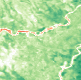

In [168]:
# One colour per class, used in every figure of the notebook
COLOURS = {"seasonal crop": "#2B580C", "stable vegetation": "#7B4F9E", "river sandbar": "#D9732B"}

# An interactive map of the whole window, still without pixels: zoom in and click to read coordinates.
# {} = an empty dictionary of pixels; background = our median NDVI map as a semi-transparent layer
window_map = tt.map_pixels(cube, {}, background=median_map)
window_map                                                      # writing the variable on the last line shows the map

**Your three points** (latitude first, then longitude, as the popup shows them). The cell below already has three points chosen on the image for Saldaña: a rice paddy, riparian forest and a sand bar of the river. To choose others (or to work on your own study area), click on the map and replace the numbers. The cell finds the MODIS pixel that contains each point; the next one saves the result in `my_pixels.json`, so that Part B uses the same pixels.

In [169]:
# The three points chosen on the high-resolution image: (latitude, longitude) in degrees.
# To use other points, click on the map above and replace the numbers (latitude first).
MY_POINTS = {
    "seasonal crop":     (3.9021, -75.0014),     # an irrigated rice paddy inside the district
    "stable vegetation": (3.9296, -74.9897),     # riparian forest along the river
    "river sandbar":     (3.9345, -75.0226),     # a sand bar (arenal) on the bank of the river
}

PIXELS = {}                                       # name -> (row, column) of the MODIS pixel
for name in MY_POINTS:
    if MY_POINTS[name] is None:
        # No point written: there is no automatic rule for every class, so ask for one
        print(f"{name:18s}: write a (latitude, longitude) for this class in MY_POINTS")
        continue
    lat, lon = MY_POINTS[name]                    # unpack the two numbers of the point
    # lonlat_to_pixel converts degrees to the UTM metres of the cube and finds the pixel that contains them
    PIXELS[name] = tt.lonlat_to_pixel(cube, lon, lat)
    print(f"{name:18s}: point ({lat}, {lon}) -> pixel (row, col) = {PIXELS[name]}")

seasonal crop     : point (3.9021, -75.0014) -> pixel (row, col) = (45, 33)
stable vegetation : point (3.9296, -74.9897) -> pixel (row, col) = (33, 38)
river sandbar     : point (3.9345, -75.0226) -> pixel (row, col) = (31, 23)


In [170]:
# Save the choice in a small text file (JSON), so that Part B uses exactly the same pixels
import json
choice = {}
for name in PIXELS:
    choice[name] = list(PIXELS[name])             # JSON stores lists, not tuples: (row, col) -> [row, col]
with open("my_pixels.json", "w") as f:            # "w" = write (it replaces the file if it exists)
    json.dump(choice, f, indent=1)
print("Saved in my_pixels.json:", PIXELS)

Saved in my_pixels.json: {'seasonal crop': (45, 33), 'stable vegetation': (33, 38), 'river sandbar': (31, 23)}


**Check 1 · On the image.** Each pixel is drawn as its real 250 m square, in the colour of its class. Is each square inside **one** land cover? Zoom in.


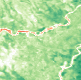

In [171]:
# The same map, now with each chosen pixel drawn as its real 250 x 250 m square, in the colour of its class.
# Zoom in: is each square inside ONE land cover, or does it mix a paddy, a road, water or sand?
pixel_map = tt.map_pixels(cube, PIXELS, COLOURS, background=median_map)
pixel_map

**Check 2 · With the data.** The typical year of each pixel (median of each composite over the 15 years) and its band of normal values. Compare with the table above: does each curve have the shape of its class? If a "seasonal crop" curve is flat, or a "forest" curve has deep troughs, go back to the map and choose another point.

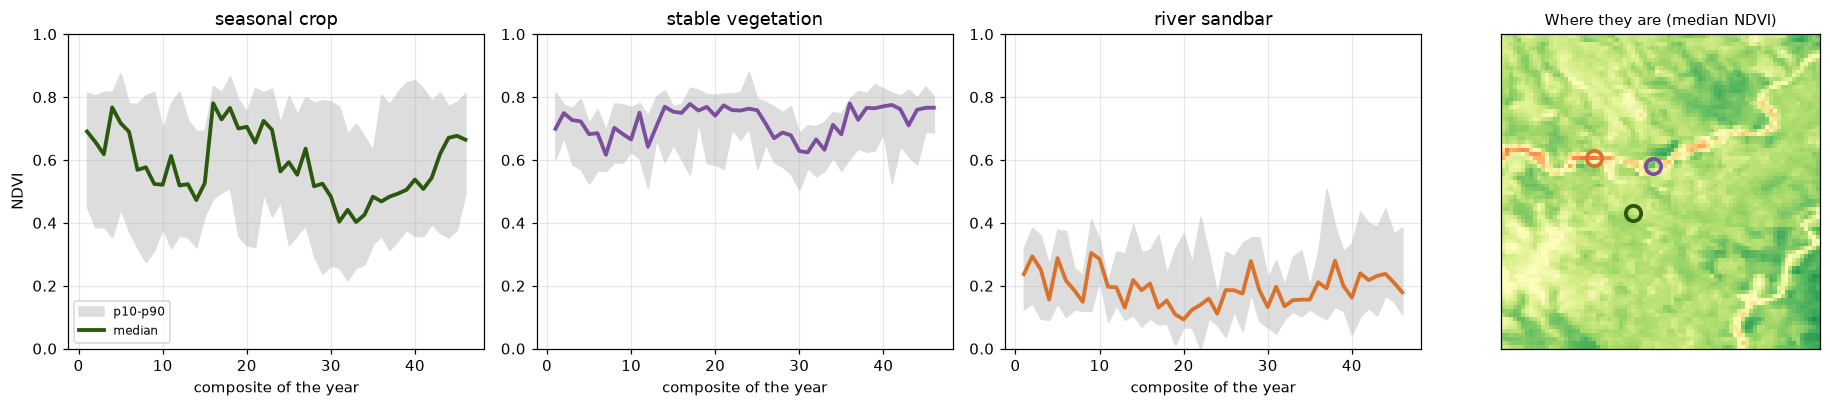

In [172]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 0.9]})
for ax, name in zip(axes[:3], PIXELS):            # one panel per pixel (zip pairs each panel with a name)
    row, col = PIXELS[name]
    # the series of the pixel as a table: one row per year, one column per composite (1...46)
    t = tt.year_period_table(ndvi[:, row, col], dates)
    # down each column: the 10th and 90th percentiles (grey band) and the median (line) of the 15 years
    ax.fill_between(t.columns, t.quantile(0.1), t.quantile(0.9), color="#DDDDDD", label="p10-p90")
    ax.plot(t.columns, t.median(), color=COLOURS[name], lw=2.5, label="median")
    ax.set_ylim(0, 1); ax.set_title(name); ax.set_xlabel("composite of the year")
axes[0].set_ylabel("NDVI"); axes[0].legend(fontsize=8)

# Fourth panel: where the three pixels are, on the median NDVI map
tt.show_map(axes[3], median_map, "Where they are (median NDVI)")
for name in PIXELS:
    row, col = PIXELS[name]
    axes[3].plot(col, row, "o", ms=10, mfc="none", mec=COLOURS[name], mew=2.5)   # x = column, y = row
plt.tight_layout(); plt.show()

### A2 · The series of one pixel
`RAW` is what was observed (with holes). Moving averages and decompositions need a series **without holes**, so we also build `SERIES`: short gaps filled linearly (Session 1), long gaps filled with "a normal value for that time of year".

⚠️ Those long-gap values are normal **by construction**. We use `SERIES` only for moving averages and decompositions (A4, A5, A7, A8). The four steps of the reading (A6), the climatology and the anomalies (A9–A12) use `RAW`.

In [173]:
RAW, SERIES = {}, {}                              # two dictionaries: name -> series
for name in PIXELS:
    row, col = PIXELS[name]
    # ndvi[:, row, col] = all the dates (":") of one pixel: its time series
    RAW[name] = ndvi[:, row, col]                 # observed values, with NaN where there was no reliable value
    # the same series without holes: short gaps interpolated, long gaps filled with the typical value
    SERIES[name], n_long = tt.complete_series(RAW[name], dates, period=P)
    n_missing = np.isnan(RAW[name]).sum()         # True counts as 1, so the sum counts the NaN
    print(f"{name:18s}: {n_missing:3d} missing values, {n_long} filled with the typical value")

seasonal crop     : 196 missing values, 88 filled with the typical value
stable vegetation : 229 missing values, 90 filled with the typical value
river sandbar     : 234 missing values, 105 filled with the typical value


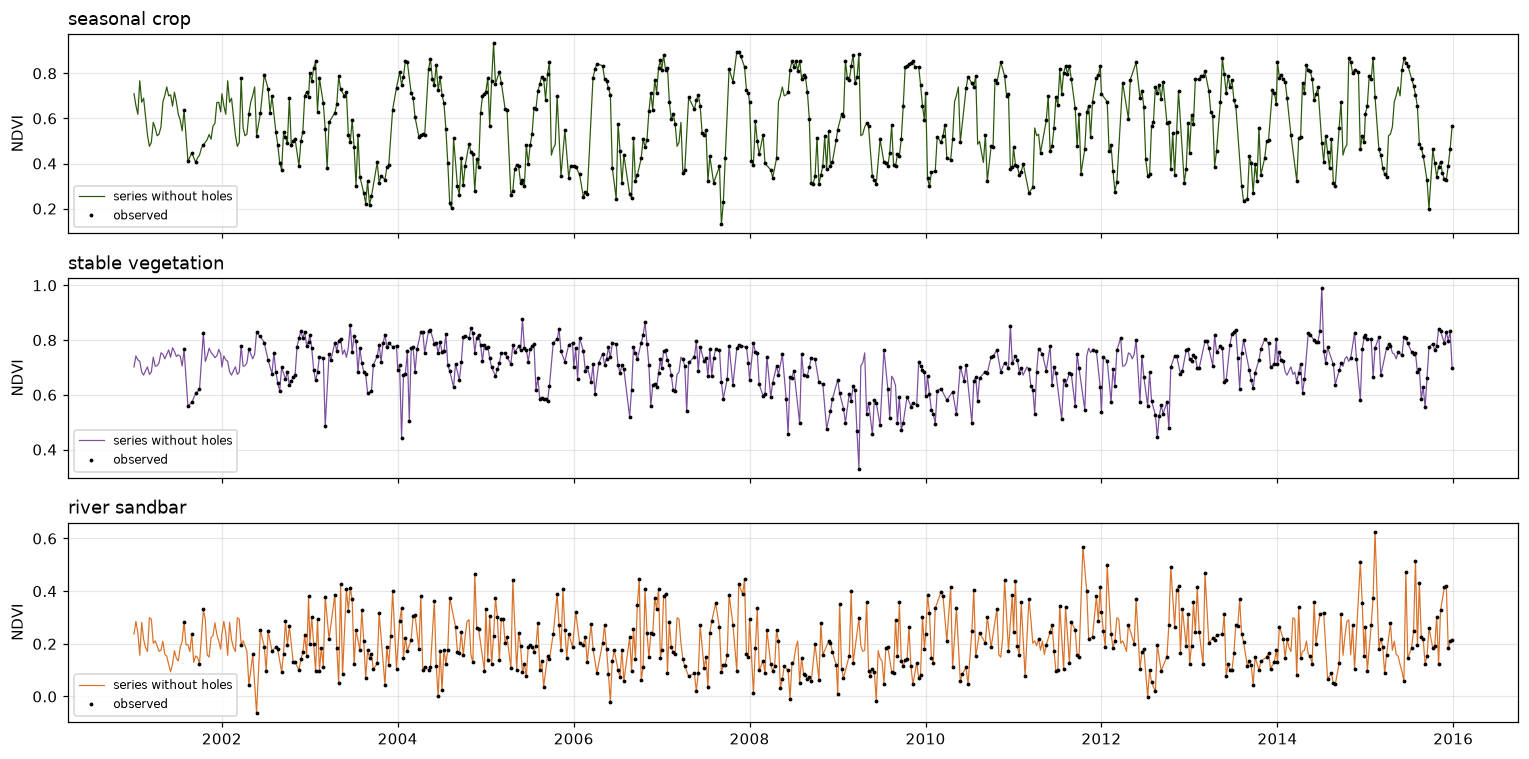

In [174]:
fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)   # three panels, one above the other, same time axis
for ax, name in zip(axes, PIXELS):
    ax.plot(dates, SERIES[name], color=COLOURS[name], lw=0.8, label="series without holes")   # line
    ax.plot(dates, RAW[name], ".", ms=3, color="k", label="observed")                       # dots: what was measured
    ax.set_ylabel("NDVI"); ax.set_title(name, loc="left"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

### A3 · The series as a table: years × composites
Each **row** is a year and each **column** is a composite of the year (1 = early January, 46 = late December). Read it in three directions:

* **along a row**: the season of that year (intra-annual scale);
* **down a column**: the same moment of the year in 15 years (inter-annual scale);
* a slow change of colour from top to bottom: a trend (long-term scale).

In [175]:
# Reshape the series of one pixel: rows = years (2001...2015), columns = composites of the year (1...46)
table = tt.year_period_table(RAW["seasonal crop"], dates)
print(table.shape)                                             # (15, 46): 15 years x 46 composites
table.iloc[:3, :8].round(2)                                    # iloc[rows, columns]: the first 3 years and 8 composites

(15, 46)


period,1,2,3,4,5,6,7,8
year,,,,,,,,
2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2003,0.8,0.77,0.82,0.85,0.63,0.78,NaN,0.67


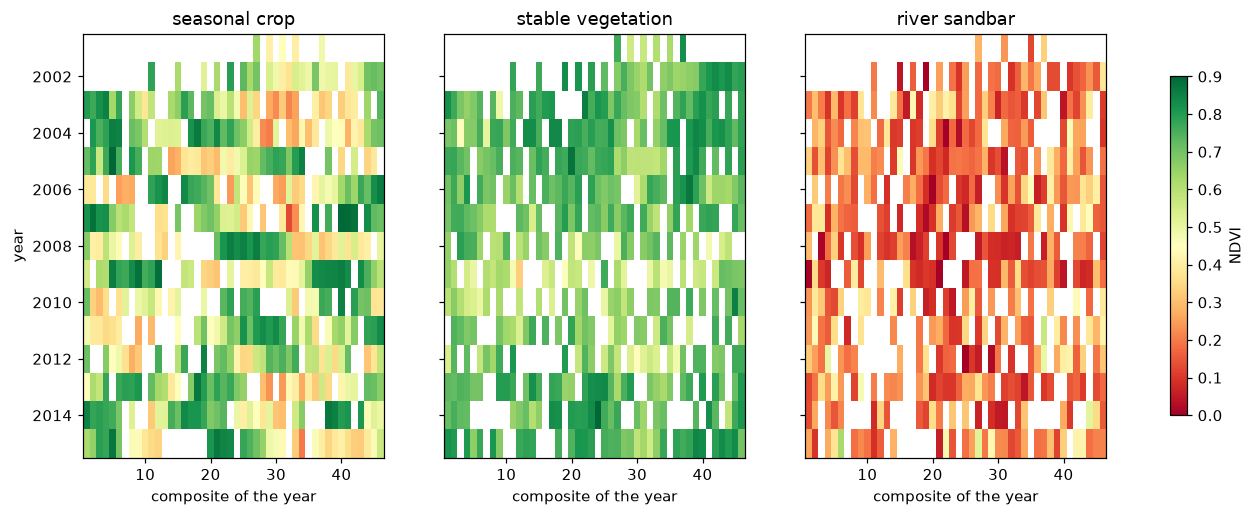

In [211]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, name in zip(axes, PIXELS):
    t = tt.year_period_table(RAW[name], dates)
    # draw the table as an image: each cell is a colour (red = low NDVI, green = high; white = no data).
    # extent puts the composites on the x axis and the years on the y axis
    im = ax.imshow(t.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=0.9,
                   extent=[0.5, P + 0.5, t.index[-1] + 0.5, t.index[0] - 0.5])
    ax.set_title(name); ax.set_xlabel("composite of the year"); ax.grid(False)
axes[0].set_ylabel("year")
plt.colorbar(im, ax=axes, shrink=0.8, label="NDVI")
plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) How many seasons per year does the seasonal crop have? (2) Find one unusual year in each pixel. Is it the same year in the three? (3) Can you see a slow change from 2001 to 2015?

### A4 · Moving average smoothing (FPP3, section 3.3)
A centred moving average of order $m = 2k + 1$ replaces each value by the mean of itself and its $k$ neighbours on each side:

$$ \hat T_t = \frac{1}{m}\sum_{j=-k}^{k} y_{t+j}. $$

What it removes depends on $m$. A short average (5 composites) removes **noise** and keeps the season. An average of **exactly one year** contains each phase of the season once, so the ups and downs **cancel**: what is left is the **trend-cycle** (the level of each year). One year is 46 composites (even), so we use the **2 × 46-MA** of A5.

First, one moving average **by hand**, for one value:

In [212]:
y = SERIES["seasonal crop"]                          # a series without holes: a moving average needs it
t = 100                                              # one position in the series (the 101st composite)
# y[t-2 : t+3] takes positions t-2, t-1, t, t+1, t+2 (Python stops BEFORE the second number)
window = y[t - 2 : t + 3]                            # the value and its 2 neighbours on each side (m = 5)
print("The 5 values:", np.round(window, 3))
print("Their mean:  ", round(window.mean(), 3))
print("The toolbox: ", round(tt.moving_average(y, 5)[t], 3))

The 5 values: [0.723 0.668 0.553 0.381 0.583]
Their mean:   0.582
The toolbox:  0.582


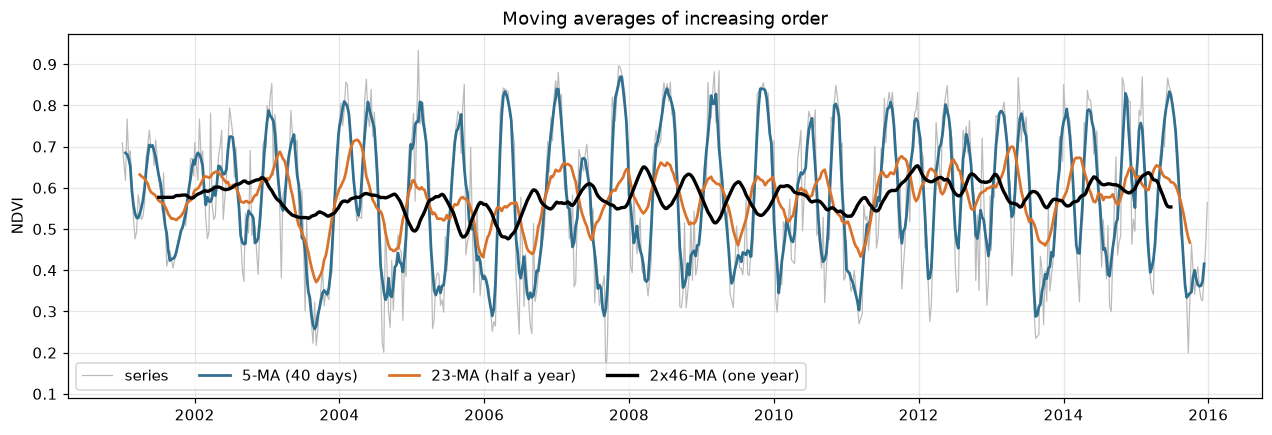

In [213]:
# The same calculation for every position, with three orders (window lengths)
plt.figure(figsize=(14, 4.3))
plt.plot(dates, y, color="#BBBBBB", lw=0.8, label="series")
plt.plot(dates, tt.moving_average(y, 5), color="#2F6F8F", lw=1.8, label="5-MA (40 days)")
plt.plot(dates, tt.moving_average(y, 23), color="#D9732B", lw=1.8, label="23-MA (half a year)")
plt.plot(dates, tt.ma_2xm(y, P), color="k", lw=2.2, label="2x46-MA (one year)")
plt.ylabel("NDVI"); plt.legend(ncol=4); plt.title("Moving averages of increasing order"); plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) Why does the half-year average still go up and down, while the one-year average does not? (2) Why is the one-year average missing at both ends? How many values are lost at each end? (3) Try a two-year average, `tt.ma_2xm(y, 92)`: what does it remove that the one-year average keeps?

*The next cell does the computation the question needs: run it, and use its result in your answer.*

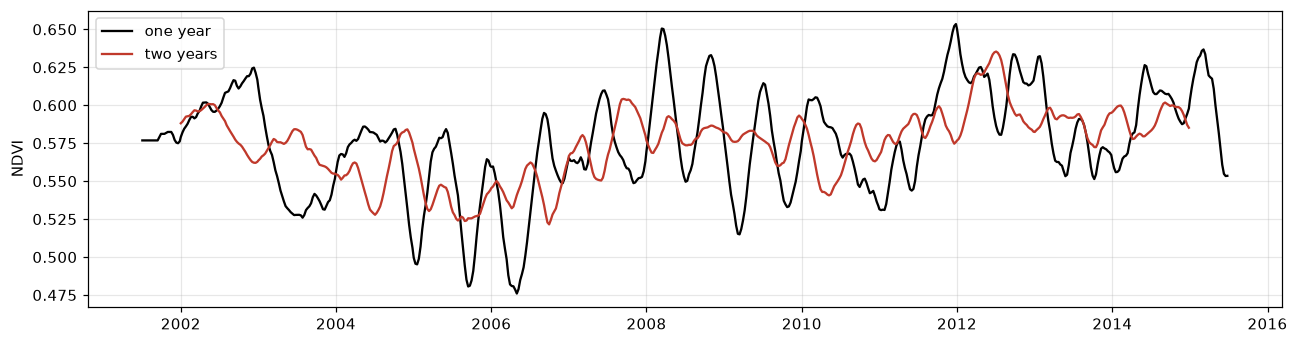

In [214]:
plt.figure(figsize=(14, 3.5))
plt.plot(dates, tt.ma_2xm(y, P), "k", label="one year")
plt.plot(dates, tt.ma_2xm(y, 2 * P), "#C0392B", label="two years")
plt.ylabel("NDVI"); plt.legend(); plt.show()

### A5 · Moving averages of moving averages, and weighted moving averages
**Even orders.** The mean of 4 values has no centre. Averaging **two consecutive** 4-MAs centres it: the result is a **2 × 4-MA**, a *weighted* average of 5 values with weights $(1, 2, 2, 2, 1)/8$. In general, a 2 × m-MA gives weight $1/(2m)$ to the two ends and $1/m$ to the rest.

**Weighted moving averages.** $\hat T_t = \sum_j a_j\, y_{t+j}$, with weights that **sum to 1** (a flat series stays flat) and are **symmetric** (nothing moves in time). Savitzky–Golay of Session 1, $(-3, 12, 17, 12, -3)/35$, is one of them.

In [215]:
# The weights of three averages with the same width (5 values)
w_simple = np.array([1, 1, 1, 1, 1]) / 5
w_2x4 = np.array([1, 2, 2, 2, 1]) / 8
w_savgol = np.array([-3, 12, 17, 12, -3]) / 35
for name, w in [("5-MA", w_simple), ("2x4-MA", w_2x4), ("Savitzky-Golay", w_savgol)]:
    print(f"{name:15s} weights = {np.round(w, 3)}   sum = {w.sum():.2f}")

5-MA            weights = [0.2 0.2 0.2 0.2 0.2]   sum = 1.00
2x4-MA          weights = [0.125 0.25  0.25  0.25  0.125]   sum = 1.00
Savitzky-Golay  weights = [-0.086  0.343  0.486  0.343 -0.086]   sum = 1.00


In [216]:
# A 2x4-MA is a 2-MA of a 4-MA: check it with numbers
x = SERIES["seasonal crop"][:12]                               # the first 12 values are enough
# np.convolve slides a set of weights along the series and adds the products:
# with weights [1/4, 1/4, 1/4, 1/4] it is the mean of every 4 consecutive values (a 4-MA, not centred)
ma4 = np.convolve(x, np.ones(4) / 4, mode="valid")
# a 2-MA of those means: the average of each pair of consecutive 4-MAs, which is centred again
ma2_of_ma4 = np.convolve(ma4, np.ones(2) / 2, mode="valid")
print("2-MA of a 4-MA :", np.round(ma2_of_ma4, 3))
print("weighted 2x4-MA:", np.round(tt.weighted_moving_average(x, w_2x4)[2:-2], 3))

2-MA of a 4-MA : [0.683 0.683 0.685 0.654 0.599 0.55  0.523 0.524]
weighted 2x4-MA: [0.683 0.683 0.685 0.654 0.599 0.55  0.523 0.524]


> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. Compute the weights of a **3 × 3-MA** (a 3-MA of a 3-MA) with `np.convolve(np.ones(3)/3, np.ones(3)/3)`. How many weights are there, and do they sum to 1?

*The next cell does the computation the question needs: run it, and use its result in your answer.*

In [217]:
# Convolving two sets of weights gives the weights of applying one average after the other
w33 = np.convolve(np.ones(3) / 3, np.ones(3) / 3)              # a 3-MA of a 3-MA
print(np.round(w33, 4), "= [1, 2, 3, 2, 1] / 9, sum =", w33.sum())

[0.1111 0.2222 0.3333 0.2222 0.1111] = [1, 2, 3, 2, 1] / 9, sum = 1.0


### A6 · The four steps of the reading, on your pixel
This section follows exactly the four figures of section 6.1 of the study guide, now with real data. At each step ask: what is removed, what is left, and which question can be answered with what is left?


| Step | Removed | Left | Question |
|---|---|---|---|
| 0 | nothing | S + I + T + ε | none yet |
| 1 | S, the typical year | the anomaly: I + T + ε | **Q1** Was this period normal? |
| 2 | ε, by averaging each year | one value per year: I + T → the Sen line is T | **Q2** Is it changing? |
| 3 | T, by subtracting the line | I | **Q3** Which years were different? |

We use the observed series (`RAW`) of one pixel. Change `name` to see the other two.

In [218]:
# STEP 0 · the series, and the typical year
name = "seasonal crop"                                  # try also "stable vegetation" or "river sandbar"
y = RAW[name]                                           # observed NDVI, one value every 8 days (with holes)

table = tt.year_period_table(y, dates)                  # rows = 15 years, columns = 46 composites
typical_year = table.median()                           # 46 values: the median of each composite over the 15 years
position = np.arange(len(y)) % P                        # 0, 1, ..., 45, 0, 1, ...: the composite of each value
S_typical = typical_year.values[position]               # the typical year, repeated every year (our S)
print("Typical year, first 6 composites:", typical_year.values[:6].round(3))

Typical year, first 6 composites: [0.691 0.657 0.618 0.767 0.717 0.69 ]


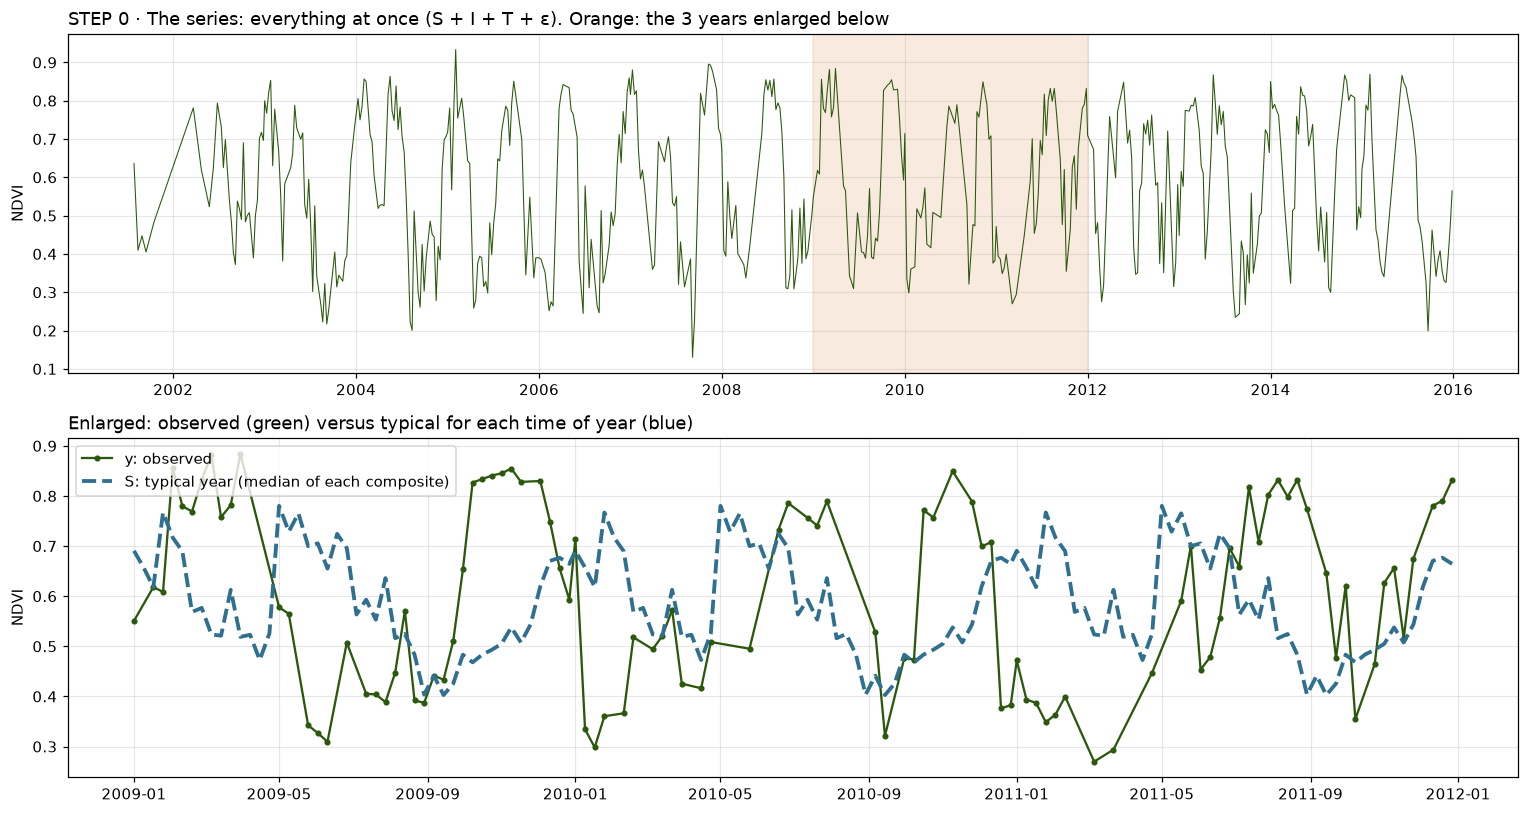

In [219]:
zoom = (dates >= "2009-01-01") & (dates < "2012-01-01")             # three years, enlarged
ok = ~np.isnan(y)                                                   # composites with a value (lines join only those)

fig, axes = plt.subplots(2, 1, figsize=(14, 7.5))
axes[0].plot(dates[ok], y[ok], color="#2B580C", lw=0.7)
axes[0].axvspan(pd.Timestamp("2009-01-01"), pd.Timestamp("2012-01-01"), color="#D9732B", alpha=0.15)
axes[0].set_title("STEP 0 · The series: everything at once (S + I + T + ε). Orange: the 3 years enlarged below", loc="left")
axes[1].plot(dates[zoom & ok], y[zoom & ok], "o-", ms=3, color="#2B580C", label="y: observed")
axes[1].plot(dates[zoom], S_typical[zoom], "--", lw=2.5, color="#2F6F8F", label="S: typical year (median of each composite)")
axes[1].set_title("Enlarged: observed (green) versus typical for each time of year (blue)", loc="left")
axes[1].legend(loc="upper left")
for ax in axes: ax.set_ylabel("NDVI")
plt.tight_layout(); plt.show()

In [220]:
# STEP 1 · remove S: subtract the typical value of each composite
a = y - S_typical                                       # the anomaly: I + T + ε

# one example, with numbers: early May 2010 (composite 17)
p = 17
i = (2010 - dates.year[0]) * P + (p - 1)                # position of composite 17 of 2010 in the series
while np.isnan(y[i]):                                   # if that composite has no data, take the next one
    i, p = i + 1, p + 1
print(f"2010, composite {p}: observed {y[i]:.3f} - typical {S_typical[i]:.3f} = anomaly {a[i]:+.3f}")

2010, composite 19: observed 0.495 - typical 0.700 = anomaly -0.205


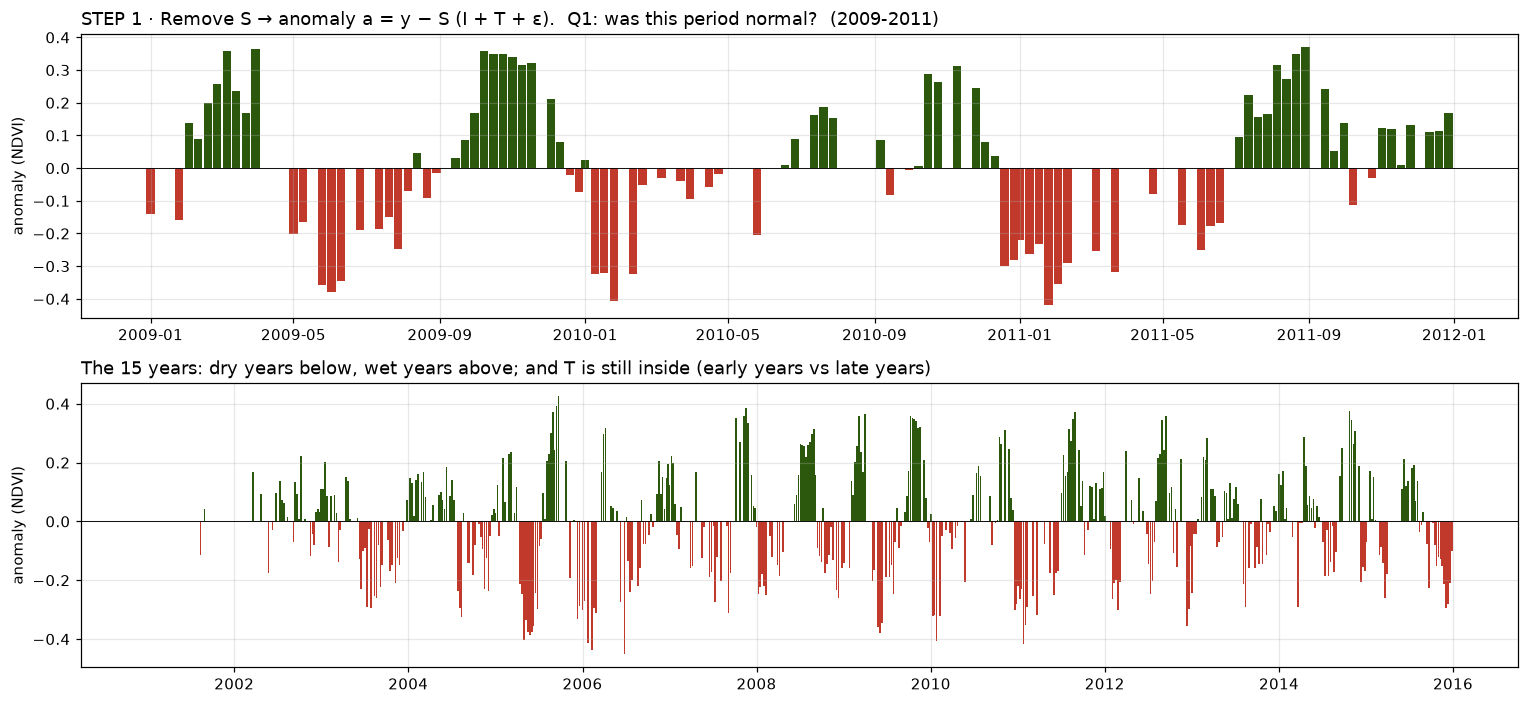

In [221]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5))
tt.bars(axes[0], dates[zoom], a[zoom], width=7)
axes[0].set_title("STEP 1 · Remove S → anomaly a = y − S (I + T + ε).  Q1: was this period normal?  (2009-2011)", loc="left")
tt.bars(axes[1], dates, a, width=7)
axes[1].set_title("The 15 years: dry years below, wet years above; and T is still inside (early years vs late years)", loc="left")
for ax in axes: ax.set_ylabel("anomaly (NDVI)")
plt.tight_layout(); plt.show()

### Step 2 · Remove ε: one value per year, and the Sen line

After step 1 the seasonal cycle S is gone. The anomaly `a` still holds three parts: **I + T + ε**.

- **ε (noise)** changes from one composite to the next. Sometimes it is up, sometimes down, and sometimes there is a missing value or a cloud.
- **I (inter-annual variation)** moves all the composites of a year together, up in a wet year and down in a dry one.
- **T (trend)** changes very slowly, over many years.

**How step 2 removes ε.** We average the 46 anomalies of each year. The ups and downs of the noise cancel out in the average, but I and T do not, because they are shared by the whole year. The result is **one value per year (15 values), which is I + T**.

**Why a line, and why the Sen line.** Look at the 15 yearly values: they rise and fall from year to year (I), and they may also drift slowly up or down (T). A straight line through them is our estimate of T, and its **slope answers question 2: is it changing?**

We do not use least squares because it squares the distances. One extreme year can pull the whole line, such as 2010 (dry) or 2011 (wet), especially if it falls at the start or end of the series. The **Theil–Sen line** is robust:

1. Compute the slope between **every pair of years**: 15 years give 105 slopes.
2. The **slope** of the line is the **median** of those 105 slopes.
3. The **intercept** is the median of (value − slope × year) over the 15 years.

The extreme pairs (2010 → 2011, for example) end up at the tails of the 105 slopes, so they do not move the median.

We report the slope in **NDVI per decade**, which is easier to read: 0.01 per year = 0.1 per decade.

> **Remember:** the slope says *how much*; it does not say whether the change is real or could be chance. That is the job of the Mann–Kendall test in Part B. Study guide: sections 6.1 (step 2) and 8.4 (the Theil–Sen line).

In [222]:
# STEP 2 · remove the noise ε: one mean per year
# a      = the anomalies of step 1 (one value per composite, 690 values = 15 years × 46)
# dates  = the date of each composite; dates.year is its year (2001, 2001, ..., 2015)
# groupby(dates.year).mean() = put the anomalies of each year together and average them.
# NaN values (no data) are ignored in the mean.
yearly = pd.Series(a).groupby(dates.year).mean()        # 15 values, one per year: I + T
print("Mean anomaly of each year (I + T):")
print(yearly.round(3).to_string())                       # round to 3 decimals; to_string() prints all years

# The Sen line through the 15 yearly values: our estimate of T
#   x = the years (yearly.index), y = the yearly means (yearly.values)
#   slope     = median of the 105 slopes between all pairs of years (NDVI per year)
#   intercept = median of (value - slope × year)
line = tt.sens_slope(yearly.values, yearly.index.values)

# The height of the line in each year: intercept + slope × year (we will draw it and, in step 3, subtract it)
T_line = line["intercept"] + line["slope"] * yearly.index.values

# × 10: from NDVI per year to NDVI per decade (easier to read); +.3f always shows the sign
print(f"\nT: {10 * line['slope']:+.3f} NDVI per decade")

Mean anomaly of each year (I + T):
2001   -0.014
2002    0.028
2003   -0.061
2004   -0.006
2005   -0.020
2006   -0.055
2007    0.021
2008   -0.019
2009    0.044
2010   -0.020
2011   -0.005
2012   -0.016
2013   -0.000
2014    0.037
2015   -0.040

T: +0.008 NDVI per decade


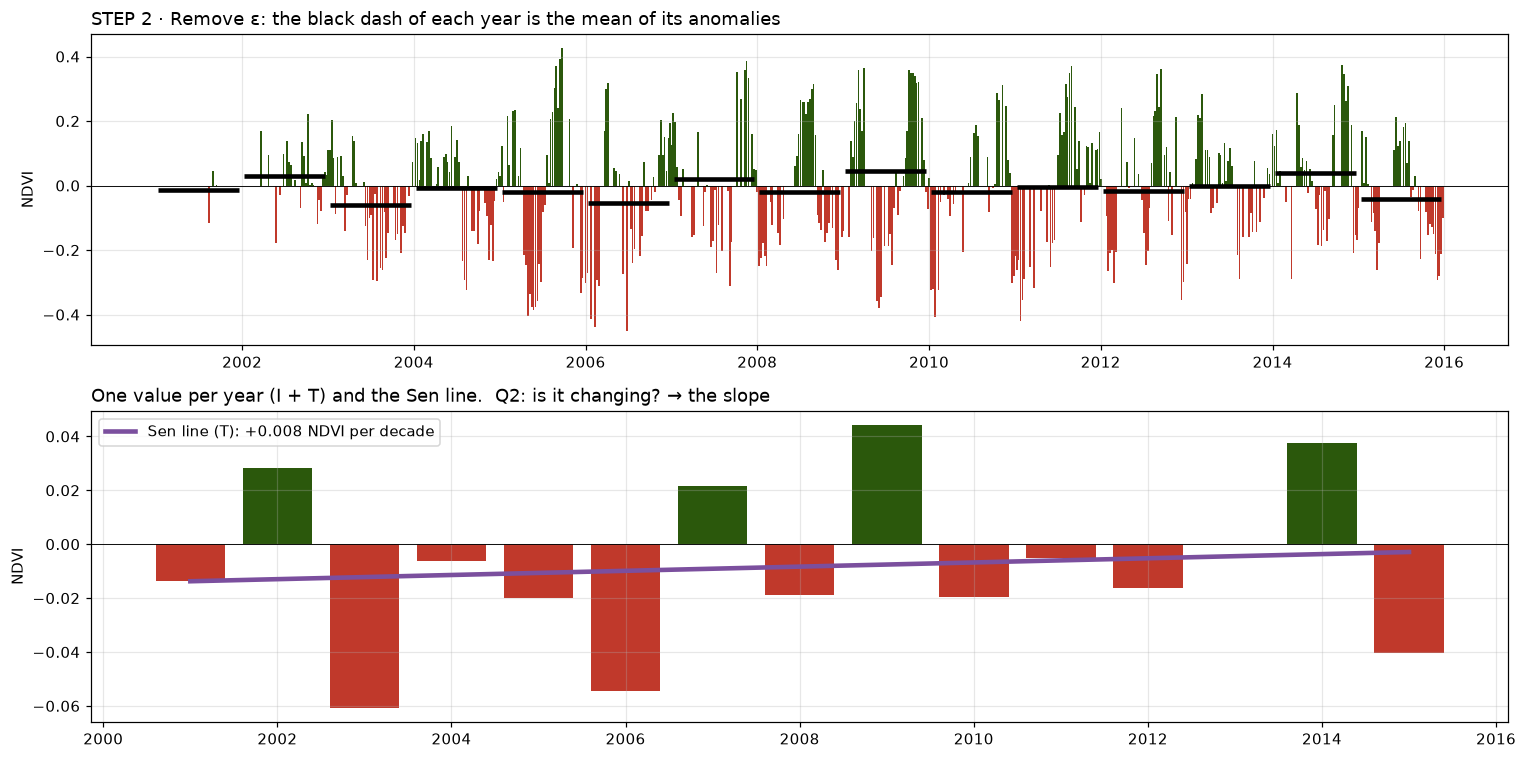

In [223]:
# Two panels, one above the other: (top) the anomalies and the mean of each year; (bottom) the 15 means and the Sen line
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Top panel: every anomaly as a thin bar (width = 7 days, almost the 8 days between composites)
tt.bars(axes[0], dates, a, width=7)
# For each year, a thick black horizontal dash at the height of its mean,
# from 10 January to 20 December, so that you can see which bars it summarises
for year, value in yearly.items():                      # .items() gives the pairs (year, mean)
    axes[0].hlines(value, pd.Timestamp(f"{year}-01-10"), pd.Timestamp(f"{year}-12-20"), color="k", lw=3)
axes[0].set_title("STEP 2 · Remove ε: the black dash of each year is the mean of its anomalies", loc="left")

# Bottom panel: the 15 yearly values as bars (I + T) and the Sen line on top (T)
tt.bars(axes[1], yearly.index, yearly.values)
axes[1].plot(yearly.index, T_line, color="#7B4F9E", lw=3,
             label=f"Sen line (T): {10 * line['slope']:+.3f} NDVI per decade")   # the legend shows the slope
axes[1].legend(loc="upper left")
axes[1].set_title("One value per year (I + T) and the Sen line.  Q2: is it changing? → the slope", loc="left")

# Both panels are in NDVI units (anomalies: above or below the typical year)
for ax in axes:
    ax.set_ylabel("NDVI")
plt.tight_layout()       # adjust the spacing so the titles do not overlap
plt.show()

Driest years (most below their trend): [(2003, -0.049), (2006, -0.045), (2015, -0.037)]
Wettest years (most above their trend): [(2002, 0.041), (2014, 0.041), (2009, 0.052)]


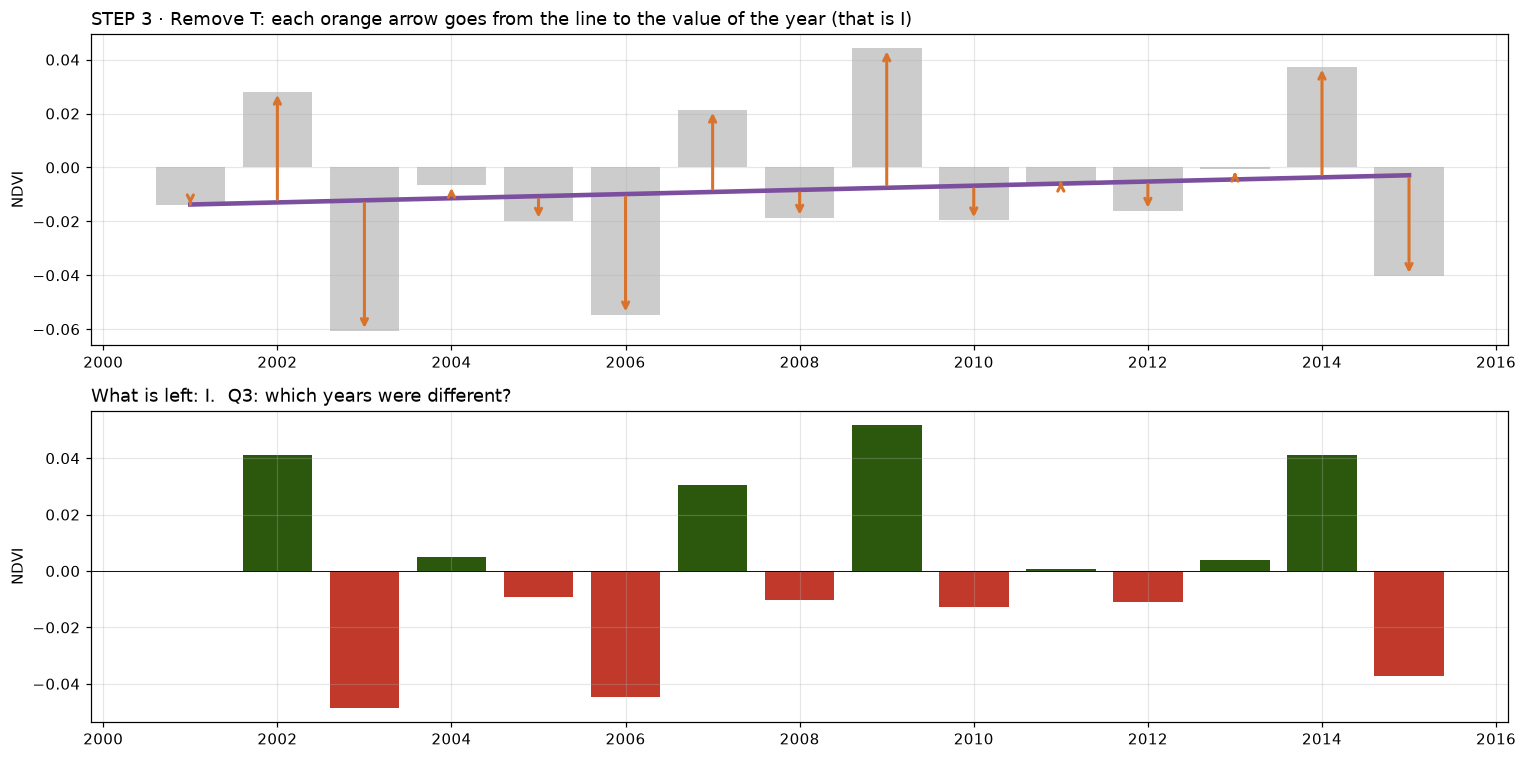

In [189]:
# STEP 3 · remove T: each year minus the line
I_years = yearly.values - T_line                        # what is left: I, how far each year was from its trend
order = np.argsort(I_years)                             # positions sorted from the most negative I to the most positive
print("Driest years (most below their trend):", [(int(yearly.index[j]), round(float(I_years[j]), 3)) for j in order[:3]])
print("Wettest years (most above their trend):", [(int(yearly.index[j]), round(float(I_years[j]), 3)) for j in order[-3:]])

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].bar(yearly.index, yearly.values, color="#CCCCCC")
axes[0].plot(yearly.index, T_line, color="#7B4F9E", lw=3)
for year, value, on_line in zip(yearly.index, yearly.values, T_line):
    # an arrow from the line (xytext) to the value of the year (xy): its length is I
    axes[0].annotate("", xy=(year, value), xytext=(year, on_line), arrowprops=dict(arrowstyle="->", color="#D9732B", lw=2))
axes[0].set_title("STEP 3 · Remove T: each orange arrow goes from the line to the value of the year (that is I)", loc="left")
tt.bars(axes[1], yearly.index, I_years)
axes[1].set_title("What is left: I.  Q3: which years were different?", loc="left")
for ax in axes: ax.set_ylabel("NDVI")
plt.tight_layout(); plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) Do the driest years coincide with El Niño (2002–03, 2009–10, 2015) and the wettest with La Niña (2007–08, 2010–11)? (2) Repeat with `name = "stable vegetation"` and `name = "river sandbar"`. In which pixel is T largest compared with I? Why might the sand bar respond to the river level (floods in La Niña) more than to the rain? What does that say about how easy it is to detect its trend?

**What comes next.** The rest of Part A looks closely at each piece: A7–A8 show other ways of separating S and T (the classical decomposition removes T first and then S; STL lets S change over the years); A9 explains the typical year (the climatology) in detail; A10–A12 the anomaly and its maps. Part B tests the line of step 2.

### A7 · Another route: the classical decomposition (FPP3, section 3.4)
A6 removed **S first** (the typical year). The classical decomposition goes in the **opposite order**: it removes **T first**, with a one-year moving average, and then estimates S from what is left. Its four steps (C1–C4, not to be confused with the steps of A6) separate $y = T + S + R$:

| Step | What is done | Compare with A6 |
|---|---|---|
| **C1** | **Trend-cycle** $\hat T$: the one-year moving average (2 × 46-MA) | A6 estimated T only at the end, as a straight line |
| **C2** | **Remove it**: $y - \hat T$. Only the season and the rest are left | — |
| **C3** | **Seasonal component** $\hat S$: for each composite, the **mean** of C2 over all years, centred on 0, repeated every year | A6 used the **median** of the observed values (the typical year) |
| **C4** | **Remainder** $\hat R = y - \hat T - \hat S$: everything else, **including the unusual years** | close to the anomaly of A6 minus T |

The figure at the end shows the four results in the order C1 → C3 → C4. We use the **additive** model: the size of the NDVI season does not grow with the level of the series.

In [224]:
y = SERIES["seasonal crop"]                     # the series without holes (a moving average needs it)

# C1 - trend-cycle: one-year moving average (P = 46 is even, so a 2 x 46-MA)
T = tt.ma_2xm(y, P)                               # NaN in the first and last 23 values: no full window there

# C2 - remove it
detrended = y - T

In [225]:
# C3 - the seasonal component: mean of each composite over the years
position = np.arange(len(y)) % P                  # 0, 1, ..., 45, 0, 1, ... : the composite of each value
seasonal_means = np.zeros(P)                     # 46 empty slots, one per composite
for p in range(P):
    # position == p selects composite p of every year; nanmean averages them ignoring the NaN of the ends
    seasonal_means[p] = np.nanmean(detrended[position == p])
seasonal_means = seasonal_means - seasonal_means.mean()     # centred on zero
S = seasonal_means[position]                                # repeated every year
print("Seasonal component, first 6 composites:", np.round(seasonal_means[:6], 3))

Seasonal component, first 6 composites: [0.084 0.048 0.029 0.084 0.066 0.033]


Same result as the toolbox? True


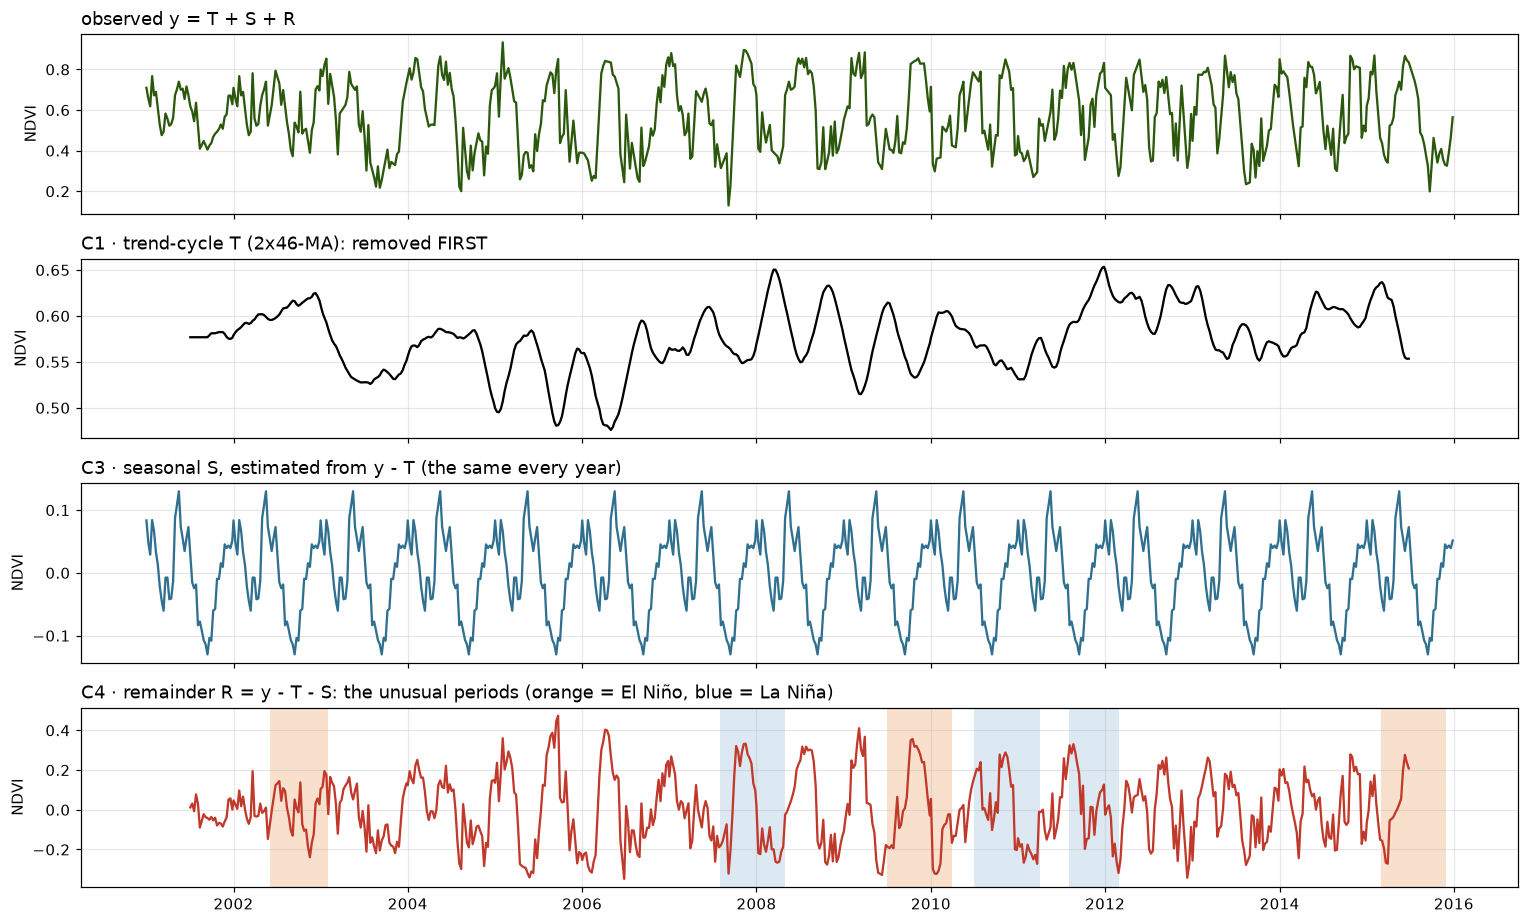

In [226]:
# C4 - what is left: the remainder
R = y - T - S
# np.allclose compares two arrays number by number (equal_nan=True: NaN in the same place count as equal)
print("Same result as the toolbox?", np.allclose(R, tt.classical_decomposition(y, P)["remainder"], equal_nan=True))

fig, axes = plt.subplots(4, 1, figsize=(14, 8.5), sharex=True)
axes[0].plot(dates, y, color="#2B580C"); axes[0].set_title("observed y = T + S + R", loc="left")
axes[1].plot(dates, T, color="k"); axes[1].set_title("C1 · trend-cycle T (2x46-MA): removed FIRST", loc="left")
axes[2].plot(dates, S, color="#2F6F8F"); axes[2].set_title("C3 · seasonal S, estimated from y - T (the same every year)", loc="left")
axes[3].plot(dates, R, color="#C0392B"); axes[3].set_title("C4 · remainder R = y - T - S: the unusual periods (orange = El Niño, blue = La Niña)", loc="left")
tt.shade_enso(axes[3], ENSO)
for ax in axes: ax.set_ylabel("NDVI")
plt.tight_layout(); plt.show()

**Four weaknesses of the classical decomposition** (FPP3), all visible above: (1) no trend in the first and last half-year; (2) fast changes are spread over a year; (3) the season is **the same every year** — if farmers now sow earlier, the change goes into the remainder; (4) one extreme year pulls the seasonal means of every year. Statistical agencies use refined versions (X-11, SEATS); in remote sensing the usual one is **STL**.

### A8 · STL (FPP3, section 3.6)
STL replaces the moving averages by **loess** (local regressions) and gives: a trend to the ends, a season that **can change slowly**, and a **robust** option that down-weights unusual values. Two choices:

* `seasonal` (odd): how many **years** are used for each seasonal value. Small = the season can change quickly.
* `trend` (odd): how many **composites** are used for the trend. If you leave it out, STL chooses one.

⚠️ The STL trend is a **smooth curve**: it describes, it does not test (that is Part B).

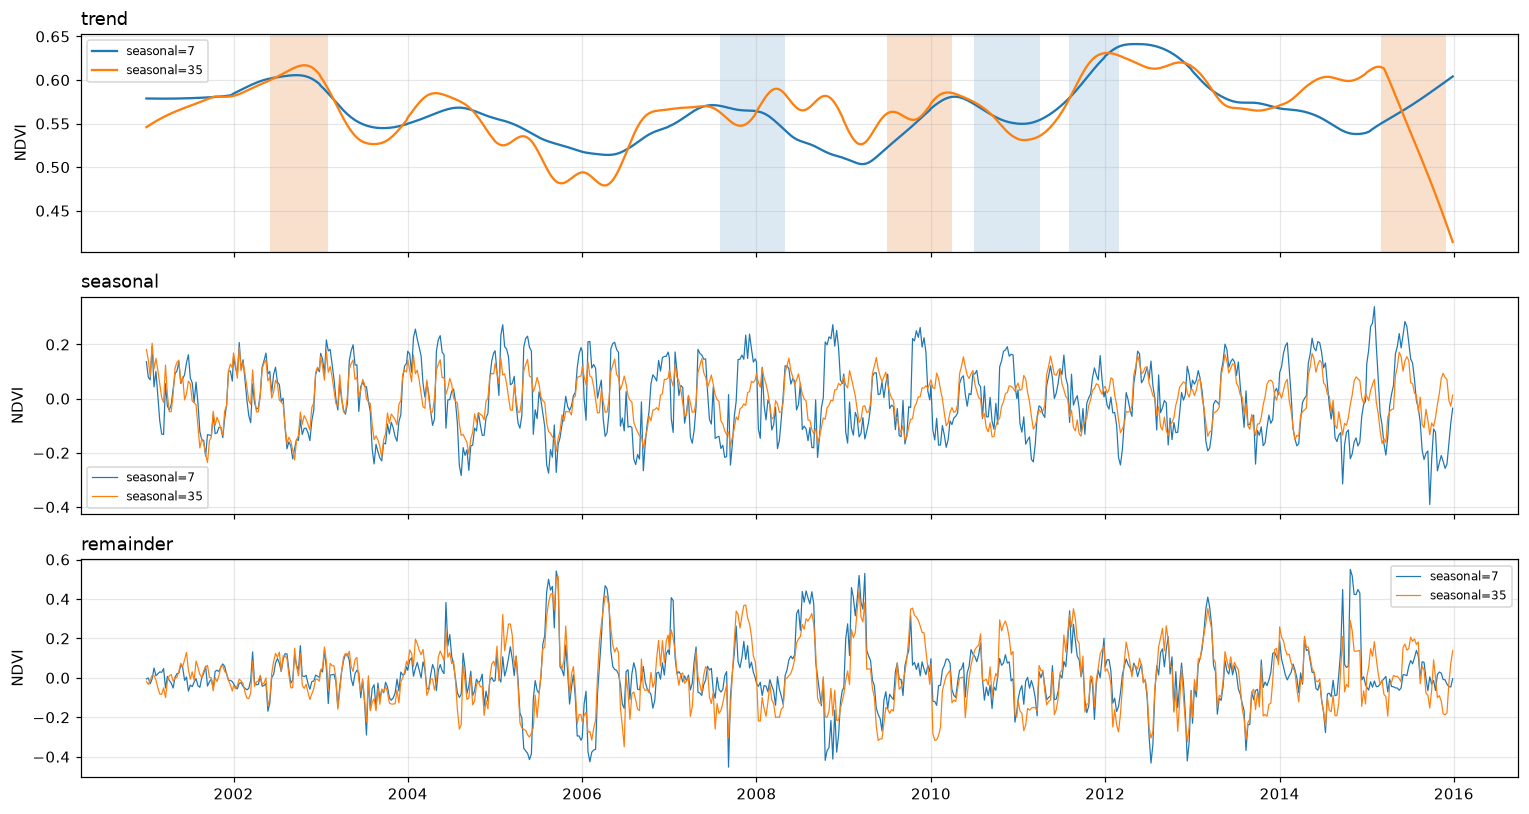

In [227]:
from statsmodels.tsa.seasonal import STL          # needs the library statsmodels (see the first cell)

s = pd.Series(SERIES["seasonal crop"], index=dates)  # STL wants a series without holes, with its dates
# period = values per year (46); seasonal = how many YEARS are used for each seasonal value (odd number);
# robust = True gives less weight to unusual values. .fit() runs the decomposition.
stl_flexible = STL(s, period=P, seasonal=7, robust=True).fit()     # 7 years: the season may change
stl_rigid = STL(s, period=P, seasonal=35, robust=True).fit()       # 35 years: almost the same season every year
# each result has three series: .trend, .seasonal and .resid (the remainder)

fig, axes = plt.subplots(3, 1, figsize=(14, 7.5), sharex=True)
for fit, label in [(stl_flexible, "seasonal=7"), (stl_rigid, "seasonal=35")]:
    axes[0].plot(dates, fit.trend, label=label)
    axes[1].plot(dates, fit.seasonal, lw=0.8, label=label)
    axes[2].plot(dates, fit.resid, lw=0.8, label=label)
tt.shade_enso(axes[0], ENSO)
for ax, title in zip(axes, ["trend", "seasonal", "remainder"]):
    ax.set_title(title, loc="left"); ax.legend(fontsize=8); ax.set_ylabel("NDVI")
plt.tight_layout(); plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) In which years does the STL trend go down? Do they coincide with El Niño? Is that a "trend"? (2) With `seasonal=7` the seasonal panel changes shape over the years: what could cause that in a rice district? (3) Run STL with `robust=False`: where does the remainder change most?

### A9 · Climatology: the typical year
The **climatology** of a pixel is its typical value for each composite of the year, over a **reference period** (here all 15 years, 2001–2015: we declare it). For each column of the table (each composite) we compute:

* the **median** of the 15 years: the expected value, `clim`;
* the **10th and 90th percentiles**: the band of normal values;
* the **robust spread** $\sigma_p = 1.4826 \times \text{MAD}$ (explained in A10).

We use `RAW`: the climatology is built only from what was observed.

In [228]:
table = tt.year_period_table(RAW["seasonal crop"], dates)        # observed values: years x composites
# For each COLUMN (composite) of the table, over the reference years:
#   centre = median, low = 10th percentile, high = 90th percentile, spread = 1.4826 x MAD, n_years = years with data
clim = tt.climatology(table, ref_years=REF_YEARS, stat="median", q=(10, 90))
clim.head().round(3)        # .head() shows the first 5 rows (composites 1 to 5)

,centre,low,high,spread,n_years
period,,,,,
1,0.691,0.450,0.814,0.174,12
2,0.657,0.386,0.806,0.220,11
3,0.618,0.387,0.816,0.256,11
4,0.767,0.354,0.818,0.127,13
5,0.717,0.444,0.875,0.216,10


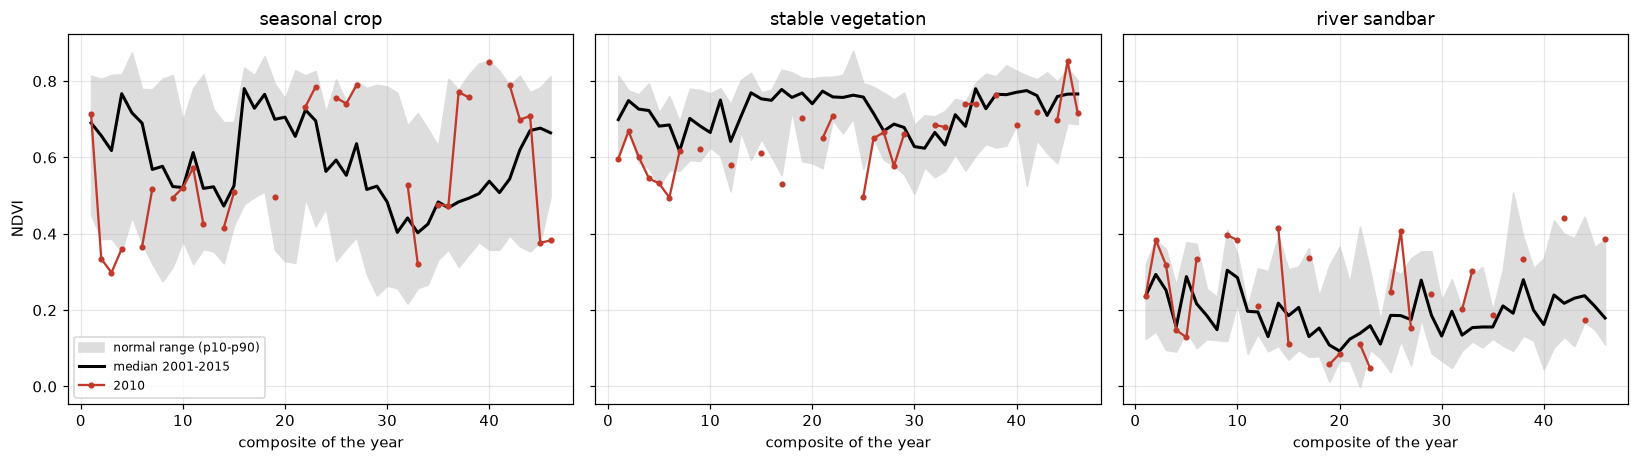

In [229]:
CLIM = {}                                         # we keep the climatology of each pixel for later sections
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, name in zip(axes, PIXELS):
    t = tt.year_period_table(RAW[name], dates)
    CLIM[name] = tt.climatology(t, ref_years=REF_YEARS)
    c = CLIM[name]                                # a short name for the table of this pixel
    ax.fill_between(c.index, c["low"], c["high"], color="#DDDDDD", label="normal range (p10-p90)")
    ax.plot(c.index, c["centre"], "k", lw=2, label="median 2001-2015")
    ax.plot(t.columns, t.loc[2010], "o-", ms=3, color="#C0392B", label="2010")
    ax.set_title(name); ax.set_xlabel("composite of the year")
axes[0].set_ylabel("NDVI"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) Compute the climatology with `stat="mean"` and compare it with the median for the seasonal crop: where do they differ most, and why? (2) Our reference uses the same years we evaluate. Why can that be a problem if there is a trend?

*The next cell does the computation the question needs: run it, and use its result in your answer.*

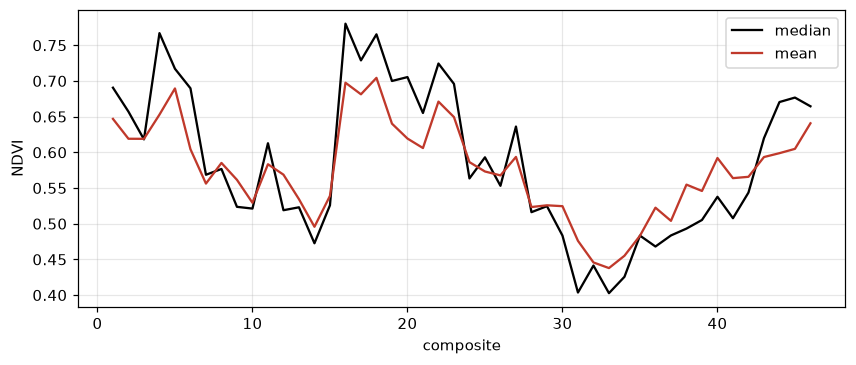

largest |mean - median|: 0.114


In [230]:
# The same climatology with the two possible centres
c_med = tt.climatology(table, REF_YEARS, stat="median")
c_mean = tt.climatology(table, REF_YEARS, stat="mean")
plt.figure(figsize=(9, 3.5))
plt.plot(c_med.index, c_med["centre"], "k", label="median")
plt.plot(c_mean.index, c_mean["centre"], "#C0392B", label="mean")
plt.legend(); plt.xlabel("composite"); plt.ylabel("NDVI"); plt.show()
print("largest |mean - median|:", round((c_mean["centre"] - c_med["centre"]).abs().max(), 3))

### A10 · The anomaly, by hand, for one composite

$$ a(t) = y(t) - \text{clim}\big(p(t)\big) \qquad\qquad z(t) = \frac{y(t) - \text{clim}\big(p(t)\big)}{\sigma_p} $$

* $a$, the **absolute anomaly**, is in NDVI units: how far above (+) or below (−) the expected value.
* $z$, the **standardised anomaly**, divides by $\sigma_p$, the **spread** of that composite between years (how much the NDVI of early May usually changes from one year to the next). $z$ has no units. Rule of thumb: $|z| < 1$ is usual, 1–2 is notable, $> 2$ is unusual.

**The robust version of $\sigma_p$.** The usual spread is the standard deviation. But the standard deviation squares the distances, so **one extreme year inflates it**. The robust alternative is the **MAD** (the median of the absolute distances to the median) times **1.4826**: for normal data without extremes it gives the same value as the standard deviation, but one extreme year cannot inflate it. It is the same estimator as the Hampel filter of Session 1.

We now do the arithmetic for **one column** of the table: composite 17 (early May) of the seasonal crop, year 2010.

In [231]:
p = 17                                          # composite 17 = early May
while np.isnan(table.loc[2010, p]):             # if 2010 has no data in that composite, take the next one
    p = p + 1
values = table[p]                               # the values of that composite, one per year
print("composite:", p, "| years with a value:", values.notna().sum())
print(values.round(3).to_string())

composite: 19 | years with a value: 12
year
2001      NaN
2002    0.523
2003    0.699
2004    0.773
2005    0.315
2006    0.735
2007    0.680
2008      NaN
2009    0.342
2010    0.495
2011    0.701
2012    0.848
2013    0.795
2014    0.775
2015      NaN


In [232]:
# 1) the expected value: the median of the 15 years
clim_p = values.median()

# 2) the absolute anomaly of 2010
y_2010 = values.loc[2010]
a = y_2010 - clim_p
print(f"clim = {clim_p:.3f}    y(2010) = {y_2010:.3f}    a = {y_2010:.3f} - {clim_p:.3f} = {a:+.3f} NDVI")

clim = 0.700    y(2010) = 0.495    a = 0.495 - 0.700 = -0.205 NDVI


In [233]:
# 3) the spread: distance of each year to the median, and the median of those distances
distances = (values - clim_p).abs()
MAD = distances.median()
sigma_robust = 1.4826 * MAD
sigma_sd = values.std()                         # the usual standard deviation, to compare
print(f"MAD = {MAD:.3f}    robust sigma = 1.4826 x {MAD:.3f} = {sigma_robust:.3f}    (standard deviation = {sigma_sd:.3f})")

# 4) the standardised anomaly
z = a / sigma_robust
print(f"z = {a:+.3f} / {sigma_robust:.3f} = {z:+.2f}")

MAD = 0.085    robust sigma = 1.4826 x 0.085 = 0.126    (standard deviation = 0.178)
z = -0.205 / 0.126 = -1.62


In [234]:
# The toolbox does the same arithmetic for every year and composite at once
z_table = tt.anomalies(table, CLIM["seasonal crop"], standardized=True)   # a table of z: years x composites
print("toolbox z for 2010, composite 17:", round(z_table.loc[2010, p], 2))

toolbox z for 2010, composite 17: -1.62


In [235]:
# Why "robust": make the lowest year much lower (an extreme year) and compare the two spreads
extreme = values.copy()                         # a copy, so the original values do not change
lowest_year = values.idxmin()                   # the year with the lowest value
extreme.loc[lowest_year] = values.min() - 0.30  # make it 0.30 lower: an extreme year
print("extreme year:", lowest_year, "->", round(extreme.loc[lowest_year], 3))
robust = 1.4826 * (extreme - extreme.median()).abs().median()
print(f"standard deviation: {values.std():.3f} -> {extreme.std():.3f}")
print(f"1.4826 x MAD      : {sigma_robust:.3f} -> {robust:.3f}")

extreme year: 2005 -> 0.015
standard deviation: 0.178 -> 0.239
1.4826 x MAD      : 0.126 -> 0.126


One extreme year inflates the standard deviation; the robust spread hardly changes. With the standard deviation, an extreme year "hides itself": it makes $\sigma_p$ larger, so its own $z$ looks smaller.

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. Repeat the arithmetic for the **stable vegetation** pixel, same composite and year. Its $a$ may be smaller than the crop's: is its $z$ also smaller? Why?

*The next cell does the computation the question needs: run it, and use its result in your answer.*

In [236]:
t_forest = tt.year_period_table(RAW["stable vegetation"], dates)
v = t_forest[p]                                         # the values of the same composite p, one per year
a_f = v.loc[2010] - v.median()                          # absolute anomaly of 2010
s_f = 1.4826 * (v - v.median()).abs().median()         # robust spread: 1.4826 x MAD
print(f"forest: a = {a_f:+.3f}, sigma = {s_f:.3f}, z = {a_f / s_f:+.2f}")
print(f"crop  : a = {a:+.3f}, sigma = {sigma_robust:.3f}, z = {z:+.2f}")

forest: a = -0.066, sigma = 0.067, z = -0.98
crop  : a = -0.205, sigma = 0.126, z = -1.62


### A11 · Anomalies of the whole series
The same arithmetic for every composite and every year: one $z$ per value. Green = above normal, red = below. Orange bands = El Niño, blue = La Niña (approximate).

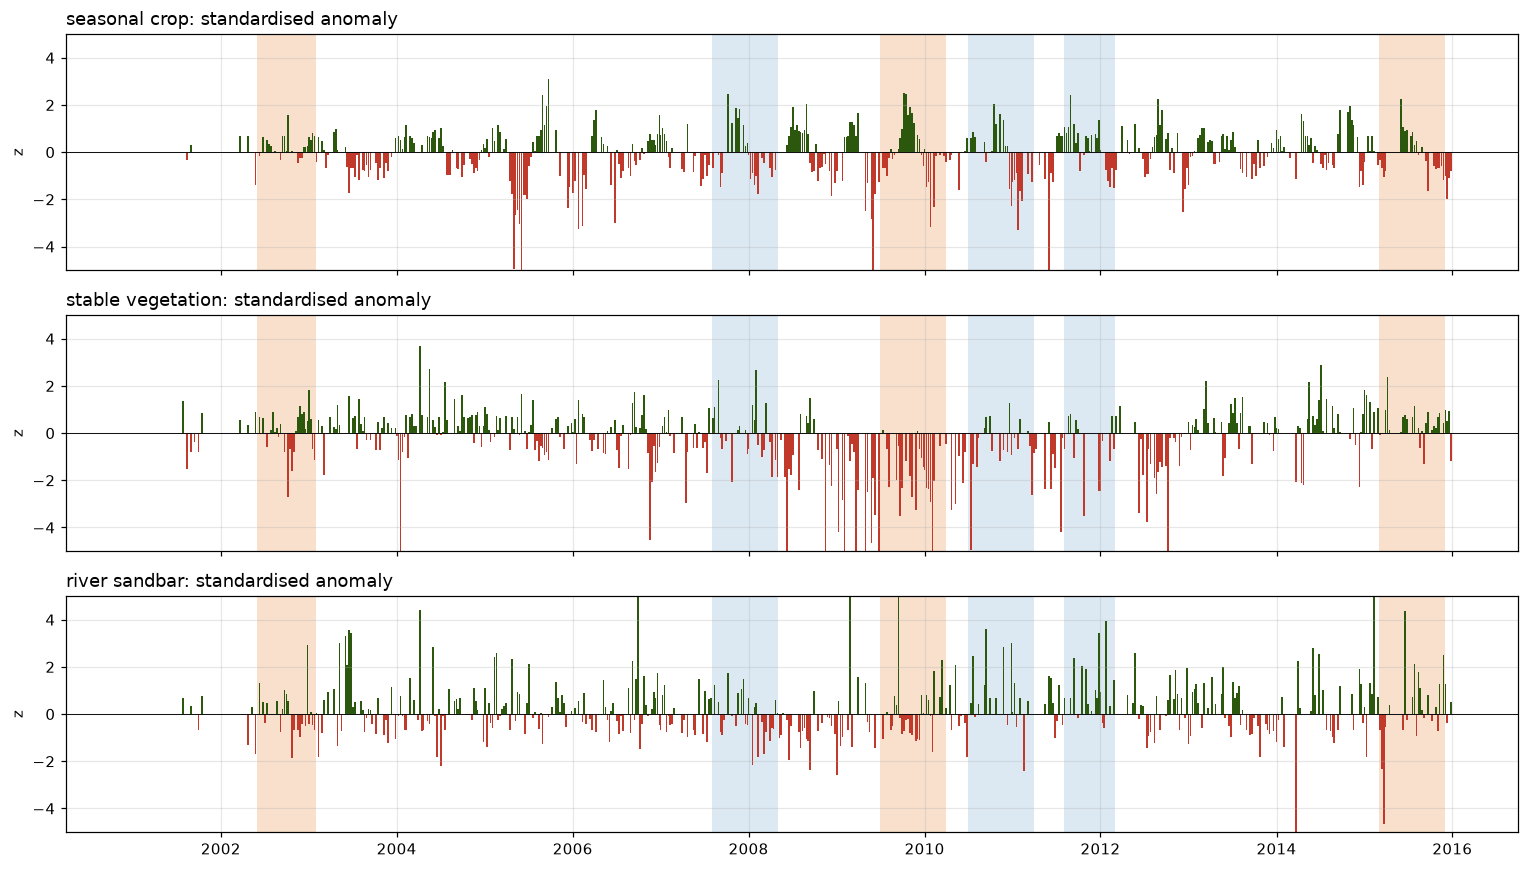

In [237]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, name in zip(axes, PIXELS):
    t = tt.year_period_table(RAW[name], dates)
    # z for every year and composite (a table), then back to one long series in time order
    z_series = tt.table_to_series(tt.anomalies(t, CLIM[name], standardized=True))
    tt.shade_enso(ax, ENSO)
    tt.bars(ax, dates[:len(z_series)], z_series, width=7)
    ax.set_ylim(-5, 5); ax.set_ylabel("z"); ax.set_title(f"{name}: standardised anomaly", loc="left")
plt.tight_layout(); plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) Do the red bars cluster in El Niño? In which pixel is the relation clearest, and in which is it weakest? Think about irrigation (the paddy) and about the river level (the sand bar: in La Niña 2010–11 the river flooded it). (2) Draw the **absolute** anomaly (`standardized=False`) of the stable vegetation: why does it look quieter than its $z$?

### A12 · Maps of anomalies: El Niño 2009–10 and La Niña 2010–11
The same $z$ for every pixel, averaged over two contrasting periods. Same colour scale: brown = below normal, green = above.

In [238]:
periods = tt.modis_period(dates, step_days=8)        # the composite number (1...46) of each layer
# the climatology of EVERY pixel: a median map and a spread map for each of the 46 composites
centre, spread = tt.climatology_cube(ndvi, dates, ref_years=REF_YEARS, periods=periods)
# z for every layer and every pixel: (value - centre of its composite) / spread of its composite
z_cube = tt.anomaly_cube(ndvi, dates, centre, spread, periods=periods)

# True/False for each layer: is it inside the period?
nino = (dates >= "2009-09-01") & (dates <= "2010-03-31")
nina = (dates >= "2010-09-01") & (dates <= "2011-03-31")
# keep only those layers and average them in time (axis=0): one mean z per pixel
z_nino = np.nanmean(z_cube[nino], axis=0)
z_nina = np.nanmean(z_cube[nina], axis=0)
print("composites in each period:", nino.sum(), nina.sum())

composites in each period: 27 27


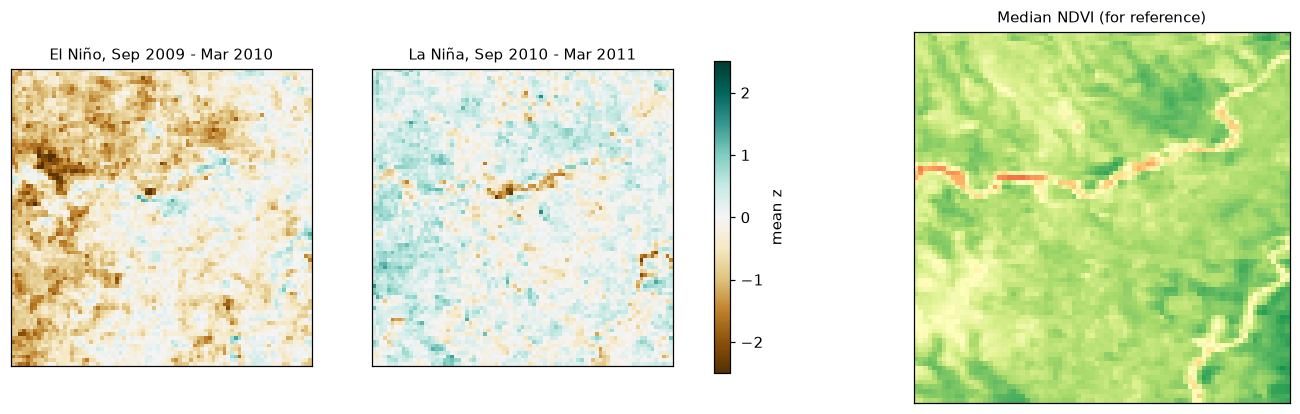

In [239]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
im = tt.show_map(axes[0], z_nino, "El Niño, Sep 2009 - Mar 2010", cmap="BrBG", vmin=-2.5, vmax=2.5)
tt.show_map(axes[1], z_nina, "La Niña, Sep 2010 - Mar 2011", cmap="BrBG", vmin=-2.5, vmax=2.5)
plt.colorbar(im, ax=axes[:2], shrink=0.8, label="mean z")
tt.show_map(axes[2], median_map, "Median NDVI (for reference)")
plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. Do the irrigated paddies (regular blocks in the median map) respond like the land around them? And the river and its sand bars? Write two sentences on irrigation and drought, and one caution about how many composites are behind each map.

### A13 · The rice trap: an anomaly of timing, not of vegetation
In Saldaña each farmer sows on a different date, and the date changes from year to year. We build a typical season and **the same season sown one month later** (4 composites of 8 days), and compute the anomaly of the late one.

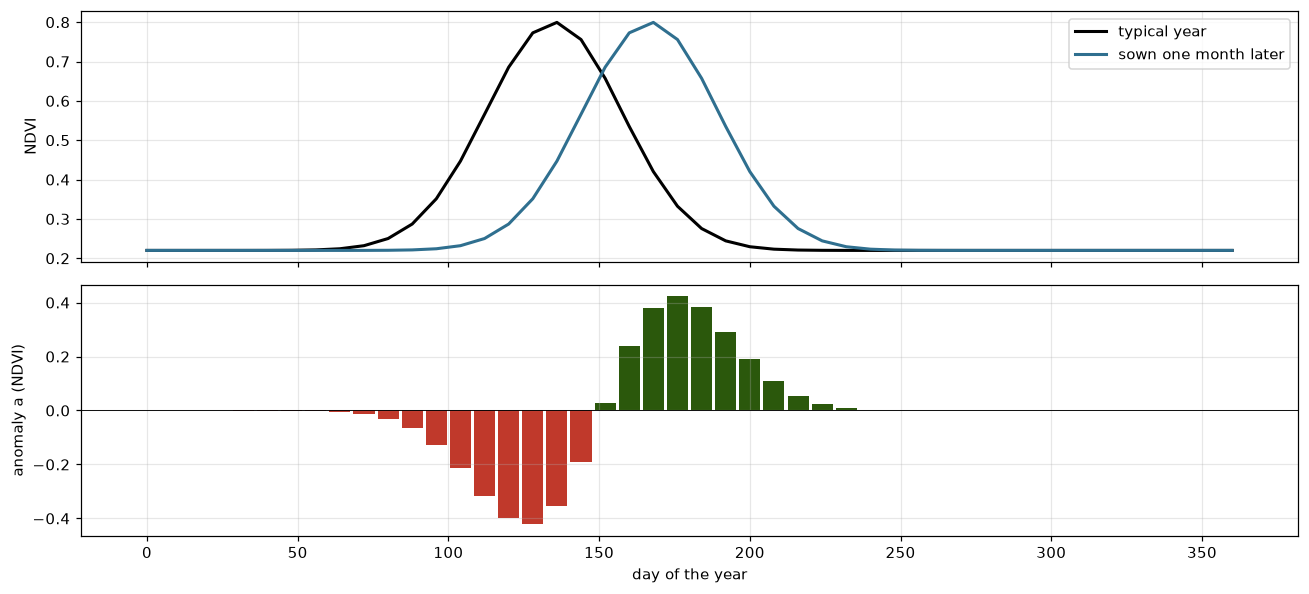

In [240]:
day = np.arange(0, 365, 8)                                      # 0, 8, 16, ...: one composite every 8 days
# A synthetic season: bare soil (0.22) plus a bell-shaped green-up of height 0.58.
# (day - 135) puts the peak on day 135 (mid-May); 32 controls how wide the season is.
typical = 0.22 + 0.58 * np.exp(-((day - 135) / 32) ** 2)        # sown early March, peak mid-May
late = 0.22 + 0.58 * np.exp(-((day - 167) / 32) ** 2)           # exactly the same season, 32 days later
anomaly = late - typical

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(day, typical, "k", lw=2, label="typical year")
axes[0].plot(day, late, "#2F6F8F", lw=2, label="sown one month later")
axes[0].set_ylabel("NDVI"); axes[0].legend()
tt.bars(axes[1], day, anomaly, width=7)
axes[1].set_ylabel("anomaly a (NDVI)"); axes[1].set_xlabel("day of the year")
plt.tight_layout(); plt.show()

In [241]:
# Composite by composite: very large anomalies
print(f"most negative anomaly: {anomaly.min():+.2f}    most positive: {anomaly.max():+.2f}")

# Season by season: the peak and the integral above bare soil (0.22)
print(f"peak:     typical {typical.max():.2f}   late {late.max():.2f}   -> anomaly {late.max() - typical.max():+.2f}")
# area under the curve above bare soil: each composite counts as a rectangle 8 days wide
integral_typical = ((typical - 0.22) * 8).sum()                 # NDVI x days
integral_late = ((late - 0.22) * 8).sum()
print(f"integral: typical {integral_typical:.0f}   late {integral_late:.0f}   (NDVI-days)")

most negative anomaly: -0.42    most positive: +0.42
peak:     typical 0.80   late 0.80   -> anomaly +0.00
integral: typical 33   late 33   (NDVI-days)


Same peak, same integral, same amount of vegetation — and yet anomalies of about −0.4 and then +0.4. **The anomaly cannot tell "less vegetation" from "vegetation at another time".** So:

* in crops, compare **seasons**: the peak, or the integral of each season, are more meaningful than composite-by-composite anomalies;
* to know **when** each season happened we need **phenology** (Session 3).

## 🌎 Apply it to your own study area — Part A

1. **Your own pixel.** Choose a pixel you can identify and repeat A9–A11 for it. Was the 2009–10 dry season (El Niño) normal there? Justify with the band of normal values, the anomaly $z$ and the number of reliable composites behind each value.
2. **Seasonal integral.** For the seasonal crop, compute the yearly integral with `tt.annual_aggregate(table, how="integral")` and its $z$ year by year (subtract the median of the 15 years, divide by 1.4826 × MAD), exactly as in A10. Is 2010 unusual by this measure? Compare with A11 and explain any difference using A13.

*The next cell does the computation the question needs: run it, and use its result in your answer.*

In [ ]:
table = tt.year_period_table(RAW["seasonal crop"], dates)
# one number per year: the area under the NDVI curve above the low base of that year
# (only years with at least 60 % of their composites)
integral = tt.annual_aggregate(table, how="integral", min_share=0.6)
centre_i = integral.median()                                  # the typical integral of the 15 years
spread_i = 1.4826 * (integral - centre_i).abs().median()      # robust spread (as in A10)
z_integral = (integral - centre_i) / spread_i                 # z of each year
print(z_integral.round(2).loc[2008:2012])

fig, ax = plt.subplots(figsize=(12, 3.5))
tt.bars(ax, z_integral.index, z_integral.values)
ax.set_ylabel("z of the yearly integral"); plt.show()

## 🧠 Self-check · Part A
Answer without running code, in your own words. If you cannot answer one, go back to the section in brackets.

1. Write the four parts of the series ($S$, $I$, $T$, $\varepsilon$) and give one example of each in a rice field of Saldaña. Which one is the largest, and why must it be removed first? (A6)
2. In step 1 we subtract the typical year. What exactly is the typical year of composite 17, and how is it computed? What is left after subtracting it? (A6, A9)
3. After step 1 we have two outputs, $a$ and $z$. What are the units of each one, and what is each one used for? (A10)
4. A pixel has $a = -0.08$ and $\sigma_p = 0.02$; another has $a = -0.08$ and $\sigma_p = 0.10$. Compute both $z$. Which one was more unusual for its own normal? (A10)
5. Why do we use $1.4826 \times$ MAD and not the standard deviation for $\sigma_p$? What would happen to the $z$ of an extreme year if we used the standard deviation? (A10)
6. Why does a moving average of exactly one year remove the seasonal cycle, while one of half a year does not? How many values are lost at each end with a 2 × 46-MA? (A4)
7. Why does an even number of composites per year need a 2 × m moving average? Write the weights of a 2 × 4-MA. (A5)
8. The classical decomposition and the steps of A6 remove the parts in a different order. Which part does each remove first? Name two weaknesses of the classical decomposition. (A6, A7)
9. The STL trend goes down in 2010 and comes back in 2011. Is that a trend? Which part of the series is it? (A8)
10. A rice pixel shows a strong negative anomaly in May and a strong positive one in July. Was it a bad year? What would you compute to know? (A13)
11. Why must the climatology and the anomalies be computed with the observed values (`RAW`) and not with the series whose long gaps were filled? (A2)
12. You chose the "seasonal crop" pixel by hand. Give two ways of checking that it really is a crop, and one reason why the high-resolution image may mislead you. (A1)

## End of Part A
We removed the seasonal cycle and measured how unusual each period was (step 1). Part B (`week10_session2_partB_trends.ipynb`) removes the noise and asks whether anything is changing over the 15 years (steps 2 and 3).